# Forecasting heart rate from a Garmin run — master notebook
**ISM-E1005 Forecasting Methods in Business Analytics, project work**

Single notebook that runs the whole analysis from the raw CSV to every figure and table in the report. Run it top to bottom (*Restart & Run All*).

| Part | Content |
|---|---|
| 1 | Data preparation, lag structure between power and HR, causal smoothing |
| 2 | Baselines, AR and ARX models, rolling-origin evaluation |
| 3 | Robustness: bootstrap, time blocks, sensitivity grid |
| 4 | Physiological state-space (Kalman) model |
| 5 | The five report figures, saved to `report_figs/` |

**Files needed in the same folder:** `run_2026-04-26.csv`, `hrlib.py` (shared feature/evaluation code), `hrss.py` (state-space model class). Part 5 writes the figure PNGs into a `report_figs/` folder it creates.
Each part re-loads the data and sets up its own variables, so the parts are self-contained.

---
# Part 1 — Data, lag structure and smoothing (steps 1–3)
*Originally `hr_forecasting_steps1-3.ipynb`.*

# Forecasting heart rate from a Garmin run — steps 1–3
**ISM-E1005 Forecasting Methods in Business Analytics, project work**

This notebook covers the first three steps of the plan:

1. Data preparation and exploratory analysis
2. Lag structure between running power and heart rate
3. Causal smoothing of the explanatory variables

**Conventions used throughout**
- 1 Hz data, 5,313 observations, one run on 2026-04-26.
- Every derived feature is *causal* (uses only information up to and including time *t*). This is verified with an explicit test in step 3.
- Forecast horizons for later steps: 1, 5, 10, 20, 30, 60, 120 s.
- Segment boundaries in this notebook are **provisional, eyeballed values** used only for description. Step 5 will test them with change-point methods.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.ar_model import ar_select_order, AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

DATA = "run_2026-04-26.csv"
HORIZONS = [1, 5, 10, 20, 30, 60, 120]

# Provisional segment boundaries (seconds) - eyeballed, to be tested in step 5
SEG_BOUNDS = {"warm-up": (0, 600), "steady": (600, 3900), "push": (3900, 5100), "cool-down": (5100, 5313)}

# Plot style: thin lines, recessive grid, colour-blind-safe hues, one y-axis per panel
COL = {"hr": "#D55E00", "power": "#0072B2", "speed": "#009E73", "cadence_spm": "#CC79A7",
       "altitude": "#6B6B6B", "grade": "#E69F00"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "grid.linewidth": .6,
                     "lines.linewidth": 1.0, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "font.size": 9.5})
SEG_SHADE = ["#00000000", "#00000012", "#00000000", "#00000012"]
def shade_segments(ax, label=False):
    for (name, (a, b)), c in zip(SEG_BOUNDS.items(), SEG_SHADE):
        ax.axvspan(a, b, color=c, lw=0)
        if label: ax.text((a + b) / 2, 1.0, name, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color="#555")

## 1. Data preparation and exploratory analysis
### 1.1 Integrity checks

In [2]:
raw = pd.read_csv(DATA)
df = raw.set_index("t").copy()
print("rows:", len(df), "| t from", df.index.min(), "to", df.index.max(), f"({df.index.max()/60:.1f} min)")
print("time step always 1 s:", bool((np.diff(df.index) == 1).all()), "| duplicate t:", int(df.index.duplicated().sum()))
print("missing values per column:\n", df.isna().sum().to_string())
print("\nDistance is non-decreasing:", bool((df.distance.diff().dropna() >= 0).all()))
print("HR range:", df.hr.min(), "-", df.hr.max(), "| HR is integer-valued:", bool((df.hr % 1 == 0).all()))
alt_steps = np.sort(df.altitude.diff().abs().round(3).unique()); print("smallest non-zero altitude step (m):", alt_steps[alt_steps > 0][:3])

rows: 5313 | t from 0 to 5312 (88.5 min)
time step always 1 s: True | duplicate t: 0
missing values per column:
 hr             0
speed          0
power          0
cadence_spm    0
altitude       0
distance       0

Distance is non-decreasing: True
HR range: 98 - 190 | HR is integer-valued: True
smallest non-zero altitude step (m): [0.2 0.4 0.6]


### 1.2 Stops, walking and sensor artefacts
A run through a city normally includes stops (traffic lights) and walking breaks. These produce abrupt drops in power, speed and cadence that are *real* events but behave differently from running. They matter for forecasting, so we list them rather than delete them.

In [3]:
def runs(mask, min_len=3):
    m = mask.values.astype(int); d = np.diff(np.r_[0, m, 0])
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    out = [(df.index[s], e - s) for s, e in zip(starts, ends) if e - s >= min_len]
    return pd.DataFrame(out, columns=["start_t", "duration_s"])

stopped = (df.speed < 0.3) & (df.power == 0)
walking = (df.cadence_spm.between(1, 130)) & (df.speed > 0.3)
print("Standing still (speed<0.3 m/s and power=0):"); print(runs(stopped).to_string(index=False))
print("\nLow-cadence episodes (1-130 spm while moving, likely walking):"); print(runs(walking, 5).to_string(index=False))
print(f"\nShare of run spent standing still: {stopped.mean():.1%} | low-cadence: {walking.mean():.1%}")

Standing still (speed<0.3 m/s and power=0):
 start_t  duration_s
    2127          15
    3343           7
    4208          21

Low-cadence episodes (1-130 spm while moving, likely walking):
 start_t  duration_s
     650          47
    1370          40
    1771          46
    3238          32
    3524          11
    3980          49
    4498          16
    5241          72

Share of run spent standing still: 0.8% | low-cadence: 5.9%


### 1.3 Descriptive statistics, overall and by provisional segment

In [4]:
VARS = ["hr", "speed", "power", "cadence_spm", "altitude"]
seg = pd.Series("", index=df.index)
for name, (a, b) in SEG_BOUNDS.items(): seg[(df.index >= a) & (df.index < b + (1 if name == "cool-down" else 0))] = name
df["segment"] = pd.Categorical(seg, categories=list(SEG_BOUNDS), ordered=True)

overall = df[VARS].describe().T[["mean", "std", "min", "50%", "max"]].round(2)
display(overall)
by_seg = df.groupby("segment", observed=True)[VARS].agg(["mean", "std"]).round(1)
by_seg.insert(0, ("n_seconds", ""), df.groupby("segment", observed=True).size())
display(by_seg)
print("Correlation matrix (levels, whole run):"); display(df[VARS].corr().round(2))

,mean,std,min,50%,max
hr,154.12,14.15,98.0,150.00,190.00
speed,2.59,0.49,0.0,2.57,4.44
power,258.60,56.49,0.0,252.00,481.00
cadence_spm,155.27,21.83,0.0,159.00,174.00
altitude,23.25,10.07,5.4,21.60,46.20


n_seconds     hr       speed       power       cadence_spm        \
                      mean   std  mean  std   mean   std        mean   std   
segment                                                                      
warm-up         600  139.9  10.8   2.5  0.3  253.4  49.5       157.2  13.8   
steady         3300  148.4   5.7   2.5  0.3  245.9  45.1       154.5  20.3   
push           1200  174.2   9.2   3.0  0.6  296.8  69.1       158.2  27.4   
cool-down       213  169.4  10.3   2.3  0.6  255.2  59.9       144.9  22.9   

          altitude        
              mean   std  
segment                   
warm-up       20.8   5.9  
steady        22.7  10.1  
push          27.3  10.8  
cool-down     15.0   4.7

Correlation matrix (levels, whole run):


,hr,speed,power,cadence_spm,altitude
hr,1.00,0.41,0.49,0.09,0.24
speed,0.41,1.00,0.54,0.68,-0.03
power,0.49,0.54,1.00,0.62,0.15
cadence_spm,0.09,0.68,0.62,1.00,-0.02
altitude,0.24,-0.03,0.15,-0.02,1.00


### 1.4 The run at a glance

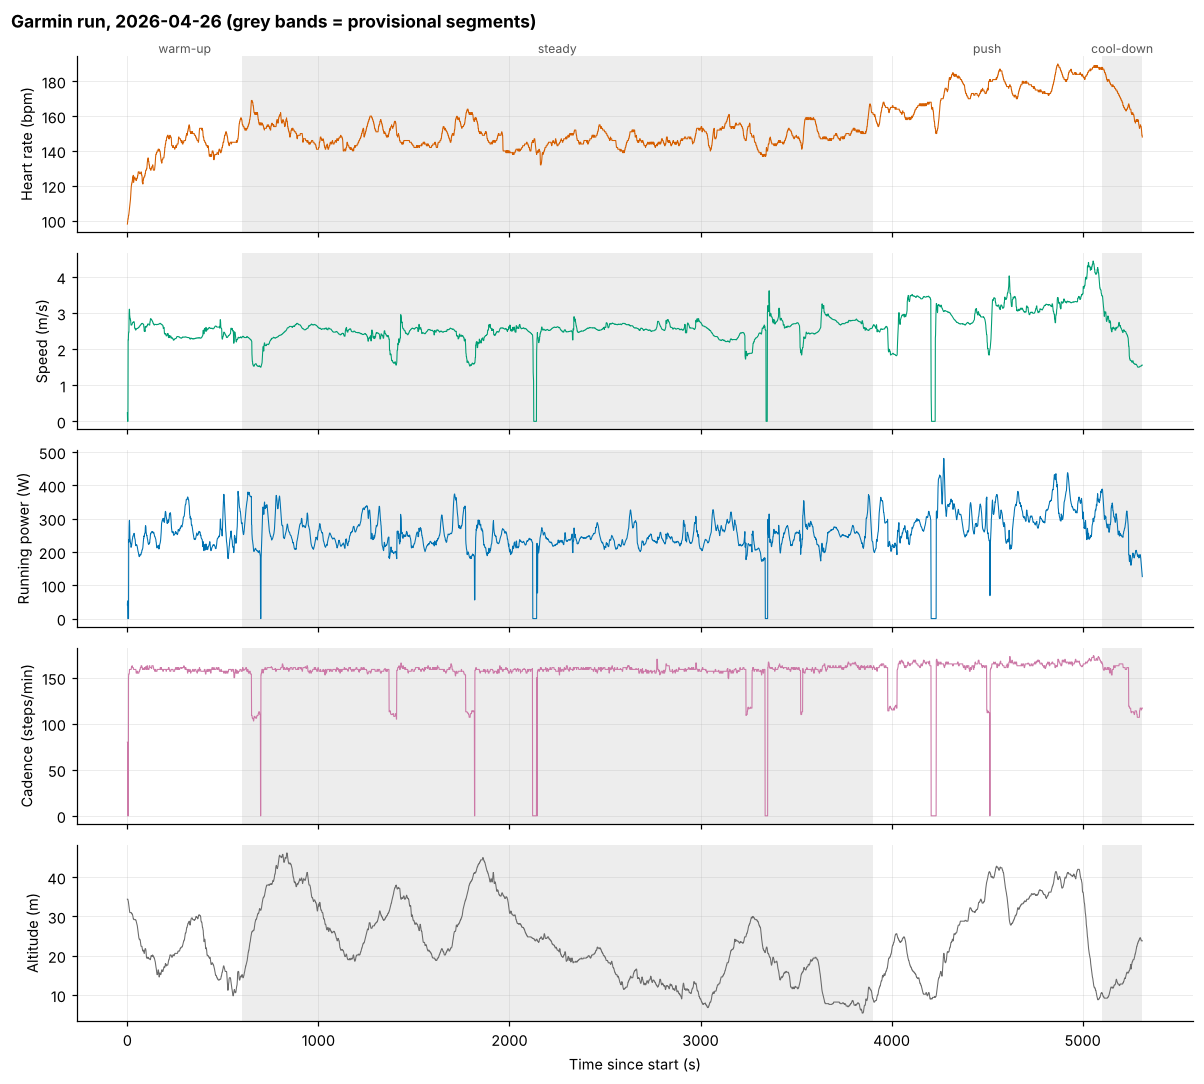

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True)
labels = {"hr": "Heart rate (bpm)", "power": "Running power (W)", "speed": "Speed (m/s)", "cadence_spm": "Cadence (steps/min)", "altitude": "Altitude (m)"}
for i, (ax, v) in enumerate(zip(axes, VARS)):
    shade_segments(ax, label=(i == 0)); ax.plot(df.index, df[v], color=COL[v], lw=.7); ax.set_ylabel(labels[v])
axes[-1].set_xlabel("Time since start (s)")
fig.suptitle("Garmin run, 2026-04-26 (grey bands = provisional segments)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

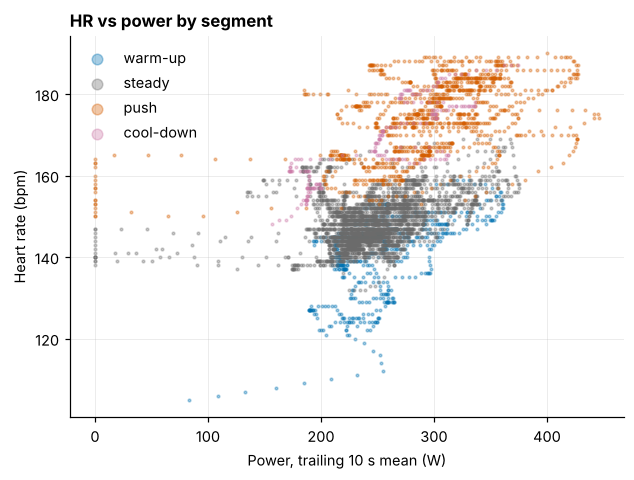

In [6]:
# HR vs power by segment: is the relationship stable across the run?
fig, ax = plt.subplots(figsize=(6.5, 4.5))
seg_cols = dict(zip(SEG_BOUNDS, ["#0072B2", "#6B6B6B", "#D55E00", "#CC79A7"]))
for s, g in df.groupby("segment", observed=True):
    ax.scatter(g.power.rolling(10).mean(), g.hr, s=3, alpha=.35, color=seg_cols[s], label=s)
ax.set_xlabel("Power, trailing 10 s mean (W)"); ax.set_ylabel("Heart rate (bpm)"); ax.set_title("HR vs power by segment")
ax.legend(markerscale=4, frameon=False); plt.show()

### 1.5 Grade from altitude (causal)
Raw altitude is quantised (0.2 m steps) and noisy, and at 1 Hz a 1 s altitude difference is meaningless. Grade is therefore computed over a trailing window of *w* seconds from a lightly smoothed altitude and the distance covered, and set to missing when the runner has barely moved.

          count  mean   std    min   25%   50%   75%    max
grade15  5269.0  0.39  5.04 -12.96 -2.69  0.10  3.34  18.77
grade30  5279.0  0.33  4.42 -11.43 -2.60  0.09  3.07  14.33
grade60  5249.0  0.25  3.74  -9.94 -2.48  0.11  2.54  12.59


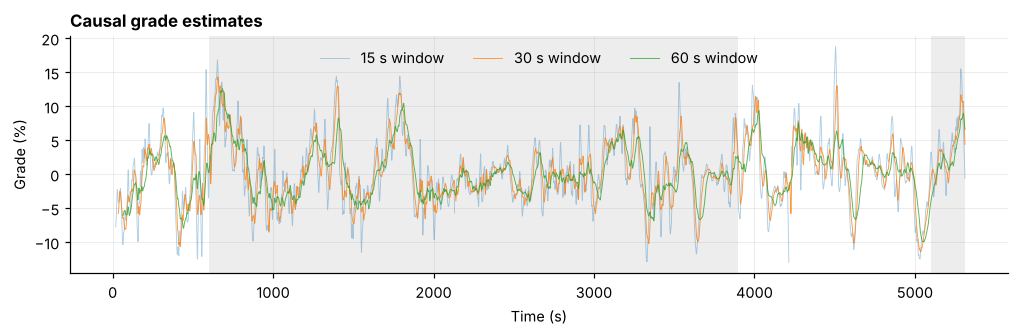

In [7]:
def causal_grade(df, w, clip=20):
    alt = df.altitude.rolling(5, min_periods=5).mean()
    dalt = alt - alt.shift(w); ddist = df.distance - df.distance.shift(w)
    g = 100 * dalt / ddist
    return g.where(ddist >= 0.5 * w).clip(-clip, clip)       # require >=0.5 m/s average movement

for w in (15, 30, 60): df[f"grade{w}"] = causal_grade(df, w)
print(df[["grade15", "grade30", "grade60"]].describe().round(2).T)
fig, ax = plt.subplots(figsize=(11, 2.8)); shade_segments(ax)
for w, a in ((15, .35), (30, .8), (60, .8)): ax.plot(df.index, df[f"grade{w}"], lw=.6, alpha=a, label=f"{w} s window")
ax.set_ylabel("Grade (%)"); ax.set_xlabel("Time (s)"); ax.set_title("Causal grade estimates"); ax.legend(frameon=False, ncol=3); plt.show()

### 1.6 Stationarity and autocorrelation

In [8]:
def stat_row(x, name):
    x = x.dropna()
    adf_c = adfuller(x, regression="c", autolag="AIC")[1]
    adf_ct = adfuller(x, regression="ct", autolag="AIC")[1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); kp = kpss(x, regression="c", nlags="auto")[1]
    return dict(series=name, ADF_p_const=adf_c, ADF_p_trend=adf_ct, KPSS_p=kp)
rows = []
for v in ["hr", "power", "speed", "cadence_spm"]:
    rows += [stat_row(df[v], v), stat_row(df[v].diff(), "Δ" + v)]
st = pd.DataFrame(rows).set_index("series")
display(st.round(4).style.format("{:.4f}").set_caption("ADF: H0 = unit root (small p -> stationary). KPSS: H0 = stationary (small p -> non-stationary). KPSS p is clipped to [0.01, 0.1]."))

,ADF_p_const,ADF_p_trend,KPSS_p
series,,,
hr,0.0017,0.0024,0.0100
Δhr,0.0000,0.0000,0.1000
power,0.0000,0.0000,0.0100
Δpower,0.0000,0.0000,0.1000
speed,0.0000,0.0000,0.0100
Δspeed,0.0000,0.0000,0.1000
cadence_spm,0.0000,0.0000,0.1000
Δcadence_spm,0.0000,0.0000,0.1000


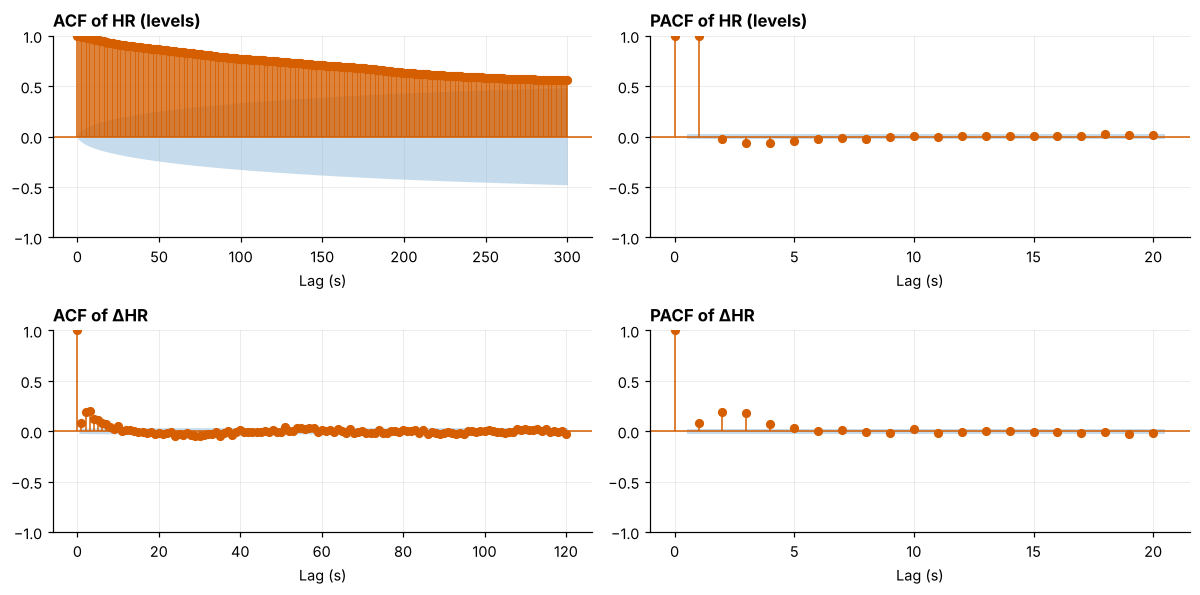

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(11, 5.5))
plot_acf(df.hr, lags=300, ax=ax[0, 0], title="ACF of HR (levels)", color=COL["hr"], vlines_kwargs={"color": COL["hr"]})
plot_pacf(df.hr, lags=20, ax=ax[0, 1], title="PACF of HR (levels)", color=COL["hr"], vlines_kwargs={"color": COL["hr"]}, method="ywm")
plot_acf(df.hr.diff().dropna(), lags=120, ax=ax[1, 0], title="ACF of ΔHR", color=COL["hr"], vlines_kwargs={"color": COL["hr"]})
plot_pacf(df.hr.diff().dropna(), lags=20, ax=ax[1, 1], title="PACF of ΔHR", color=COL["hr"], vlines_kwargs={"color": COL["hr"]}, method="ywm")
for a in ax.ravel(): a.set_xlabel("Lag (s)")
fig.tight_layout(); plt.show()

## 2. Lag structure between power and heart rate
Physiology suggests HR relaxes toward a power-dependent target with a delay. Three complementary estimates:

- **2.1 Prewhitened cross-correlation** — does power *lead* HR, and at which lags? Both series are differenced (removes the level drift) and the same AR filter is applied to both, so the cross-correlation is not driven by the input's own autocorrelation.
- **2.2 Distributed-lag regression** — ΔHR on lags of Δpower. Because differencing both sides leaves the lag coefficients unchanged, the coefficients are the *impulse response* of HR to power and their cumulative sum is the *step response* (HR response to a sustained 1 W increase).
- **2.3 First-order response model** — HR relaxes with time constant τ toward a target that depends on power delayed by *d* seconds, giving a directly interpretable (d, τ) pair.

1 s resolution: largest |r| at lags [np.int64(4), np.int64(3), np.int64(15)] s; band ±0.027; r(k=0)=0.042
5 s resolution: largest |r| at lags [np.int64(5), np.int64(15), np.int64(10)] s; band ±0.061; r(k=0)=0.096


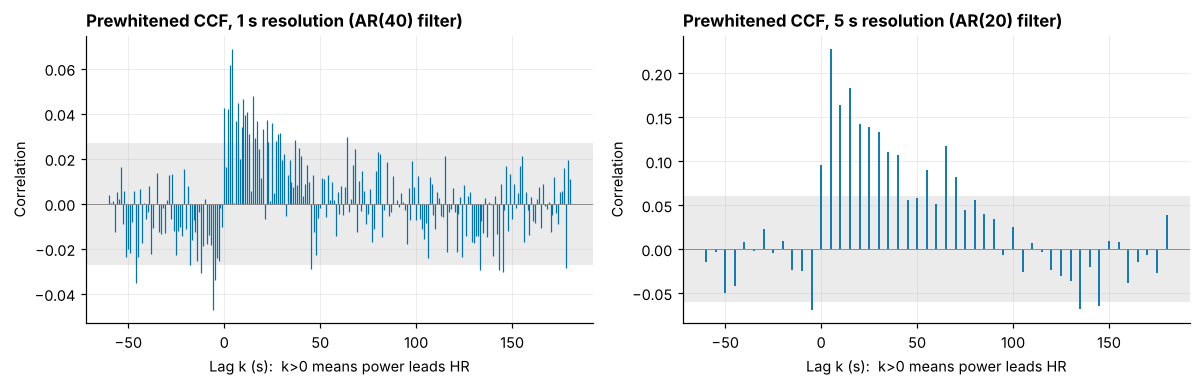

In [10]:
def prewhiten_ccf(x, y, maxlag_pos=180, maxlag_neg=60, ar_max=40):
    """x = input (power), y = output (HR). Both assumed already differenced. Positive k: x leads y."""
    x = x.dropna().values; y = y.dropna().values
    sel = ar_select_order(x, maxlag=ar_max, ic="aic", trend="n")
    p = max(sel.ar_lags) if sel.ar_lags else 1
    phi = AutoReg(x, lags=p, trend="n").fit().params
    def filt(z): n = len(z); return z[p:] - sum(phi[i - 1] * z[p - i:n - i] for i in range(1, p + 1))
    a, b = filt(x), filt(y); n = len(a)
    ks = np.arange(-maxlag_neg, maxlag_pos + 1)
    r = np.array([np.corrcoef(a[:n - k], b[k:])[0, 1] if k >= 0 else np.corrcoef(a[-k:], b[:n + k])[0, 1] for k in ks])
    return ks, r, 1.96 / np.sqrt(n), p

def block_mean(s, w): return s.groupby((s.index // w)).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, w in zip(axes, (1, 5)):
    p_, h_ = (df.power, df.hr) if w == 1 else (block_mean(df.power, w), block_mean(df.hr, w))
    ks, r, band, p = prewhiten_ccf(p_.diff(), h_.diff(), maxlag_pos=180 // w, maxlag_neg=60 // w)
    ax.axhspan(-band, band, color="#00000014", lw=0); ax.vlines(ks * w, 0, r, color=COL["power"], lw=1.2 if w > 1 else .8); ax.axhline(0, color="#888", lw=.6)
    top = ks[np.argsort(-np.abs(r))[:3]] * w
    ax.set_title(f"Prewhitened CCF, {w} s resolution (AR({p}) filter)"); ax.set_xlabel("Lag k (s):  k>0 means power leads HR"); ax.set_ylabel("Correlation")
    print(f"{w} s resolution: largest |r| at lags {list(top)} s; band ±{band:.3f}; r(k=0)={r[ks==0][0]:.3f}")
fig.tight_layout(); plt.show()

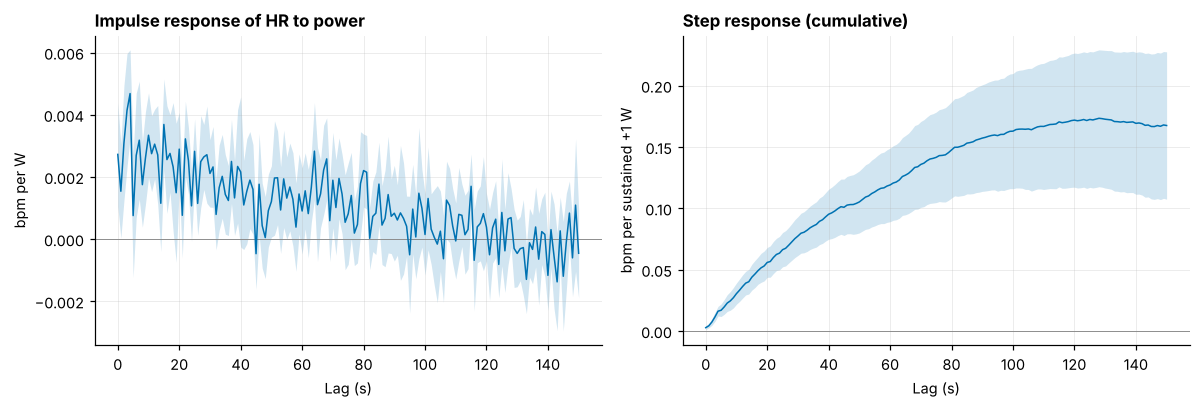

R² of distributed-lag model on ΔHR: 0.082 (n=5162)
Implied steady-state gain after 150 s: 0.167 bpm/W (95% CI 0.107 to 0.227); time to 63%: 51 s, to 90%: 84 s
Individually significant lags (|t|>1.96): [0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 20, 22, 23, 25, 26, 27, 28, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 43, 44, 46, 50, 51, 52] ...


In [11]:
K = 150                                                        # lags of power considered (s)
d_ = pd.DataFrame({"dhr": df.hr.diff()})
for k in range(K + 1): d_[f"dp{k}"] = df.power.diff().shift(k)
d_ = d_.dropna(); X = sm.add_constant(d_.drop(columns="dhr"))
dl = sm.OLS(d_.dhr, X).fit(cov_type="HAC", cov_kwds={"maxlags": 30})
b = dl.params.drop("const").values; V = dl.cov_params().drop("const").drop(columns="const").values
L = np.tril(np.ones((K + 1, K + 1))); cum = L @ b; cum_se = np.sqrt(np.diag(L @ V @ L.T))
se = np.sqrt(np.diag(V)); k_ = np.arange(K + 1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].axhline(0, color="#888", lw=.6); ax[0].fill_between(k_, b - 1.96 * se, b + 1.96 * se, color=COL["power"], alpha=.18, lw=0); ax[0].plot(k_, b, color=COL["power"])
ax[0].set_title("Impulse response of HR to power"); ax[0].set_xlabel("Lag (s)"); ax[0].set_ylabel("bpm per W")
ax[1].axhline(0, color="#888", lw=.6); ax[1].fill_between(k_, cum - 1.96 * cum_se, cum + 1.96 * cum_se, color=COL["power"], alpha=.18, lw=0); ax[1].plot(k_, cum, color=COL["power"])
ax[1].set_title("Step response (cumulative)"); ax[1].set_xlabel("Lag (s)"); ax[1].set_ylabel("bpm per sustained +1 W")
fig.tight_layout(); plt.show()
gain = cum[-1]
t63 = int(np.argmax(cum >= 0.63 * gain)) if gain > 0 else None
t90 = int(np.argmax(cum >= 0.90 * gain)) if gain > 0 else None
print(f"R² of distributed-lag model on ΔHR: {dl.rsquared:.3f} (n={int(dl.nobs)})")
print(f"Implied steady-state gain after {K} s: {gain:.3f} bpm/W (95% CI {cum[-1]-1.96*cum_se[-1]:.3f} to {cum[-1]+1.96*cum_se[-1]:.3f}); time to 63%: {t63} s, to 90%: {t90} s")
print("Individually significant lags (|t|>1.96):", [int(i) for i in k_[np.abs(b / se) > 1.96]][:40], "...")

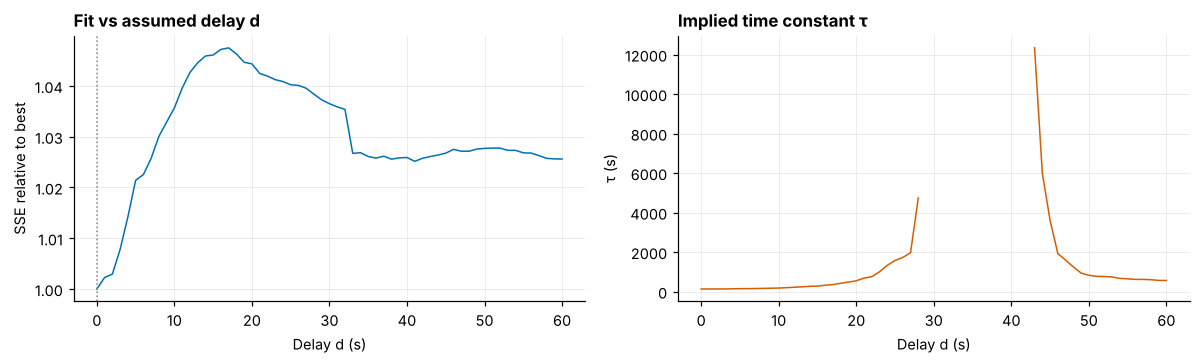

Best delay d = 0 s -> τ = 128 s, gain = 0.363 bpm/W, R² (ΔHR) = 0.054


,d,tau,gain,r2,n
segment,,,,,
warm-up,60,207.359,0.120,0.003,540
steady,0,86.641,0.216,0.032,3300
push,0,93.126,0.279,0.114,1200
cool-down,1,52.019,0.229,0.076,213


In [12]:
# First-order response with delay d:  ΔHR_t = a0 + a1*HR_{t-1} + a2*P_{t-d},  alpha=-a1 (1/tau), gain g=a2/alpha
def first_order(hr, p, d, mask=None):
    D = pd.DataFrame({"dhr": hr.diff(), "hr1": hr.shift(1), "p": p.shift(d)}).dropna()
    if mask is not None: D = D[mask.reindex(D.index).fillna(False)]
    f = sm.OLS(D.dhr, sm.add_constant(D[["hr1", "p"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 30})
    alpha = -f.params["hr1"]
    return dict(d=d, sse=f.ssr, r2=f.rsquared, alpha=alpha, tau=1 / alpha if alpha > 0 else np.nan, gain=f.params["p"] / alpha if alpha > 0 else np.nan, n=int(f.nobs))

prof = pd.DataFrame([first_order(df.hr, df.power, d) for d in range(0, 61)]).set_index("d")
d_best = int(prof.sse.idxmin())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(prof.index, prof.sse / prof.sse.min(), color=COL["power"]); ax[0].axvline(d_best, color="#888", ls=":")
ax[0].set_title("Fit vs assumed delay d"); ax[0].set_xlabel("Delay d (s)"); ax[0].set_ylabel("SSE relative to best")
ax[1].plot(prof.index, prof.tau, color=COL["hr"]); ax[1].set_title("Implied time constant τ"); ax[1].set_xlabel("Delay d (s)"); ax[1].set_ylabel("τ (s)")
fig.tight_layout(); plt.show()
print(f"Best delay d = {d_best} s -> τ = {prof.tau[d_best]:.0f} s, gain = {prof.gain[d_best]:.3f} bpm/W, R² (ΔHR) = {prof.r2[d_best]:.3f}")

# Same model by provisional segment, delay re-estimated within each segment
rows = []
for s in SEG_BOUNDS:
    m = (df.segment == s)
    best = min((first_order(df.hr, df.power, d, m) for d in range(0, 61, 1)), key=lambda r: r["sse"])
    rows.append({"segment": s, **{k: best[k] for k in ("d", "tau", "gain", "r2", "n")}})
display(pd.DataFrame(rows).set_index("segment").round(3))

### 2.4 Zooming in on a power change
A visual check on a stretch with a clear change in effort. Two stacked panels with a shared time axis (no dual axis).

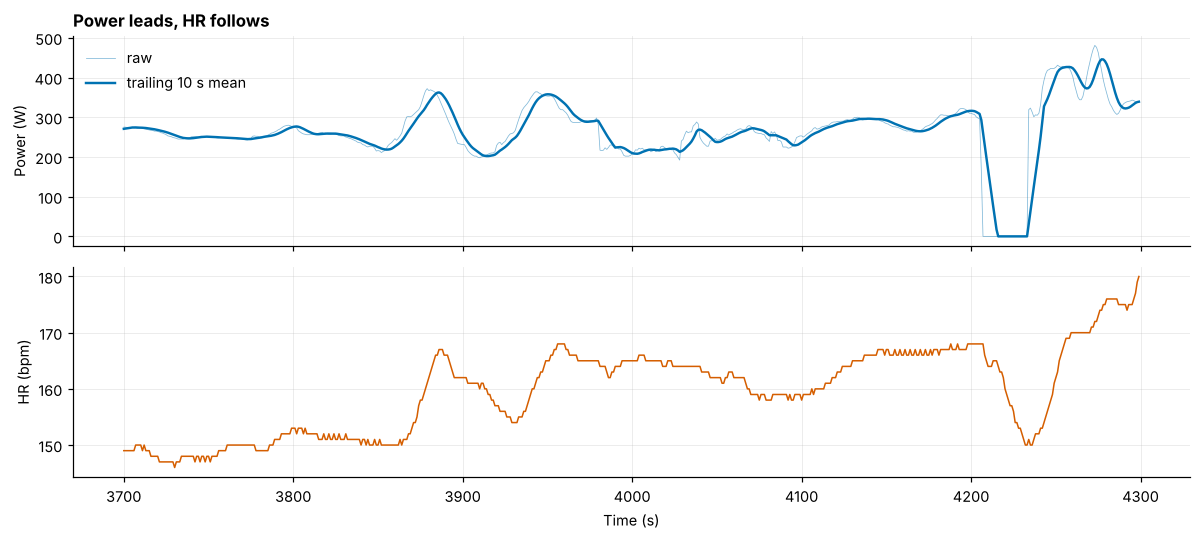

In [13]:
t0, t1 = 3700, 4300
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
ax[0].plot(df.index[t0:t1], df.power[t0:t1], color=COL["power"], lw=.5, alpha=.5, label="raw"); ax[0].plot(df.index[t0:t1], df.power.rolling(10).mean()[t0:t1], color=COL["power"], lw=1.6, label="trailing 10 s mean")
ax[0].set_ylabel("Power (W)"); ax[0].legend(frameon=False, loc="upper left"); ax[0].set_title("Power leads, HR follows")
ax[1].plot(df.index[t0:t1], df.hr[t0:t1], color=COL["hr"]); ax[1].set_ylabel("HR (bpm)"); ax[1].set_xlabel("Time (s)")
fig.tight_layout(); plt.show()

## 3. Causal smoothing of explanatory variables
Candidate smoothers for each predictor *x* (power, speed, cadence):

| Smoother | Definition at time *t* |
|---|---|
| raw | x_t |
| MA(w) | mean of x_{t-w+1..t}, w ∈ {5, 10, 30, 60} |
| EWMA(w) | exponential average with span w ∈ {5, 10, 30, 60} |

Grade uses its own trailing-window definition (15, 30, 60 s). The target HR is always left unsmoothed.

### 3.1 Leakage test
A feature is causal if changing the data *after* time t0 cannot change any feature value at or before t0.

In [14]:
def ma(x, w): return x.rolling(w, min_periods=w).mean()
def ew(x, w): return x.ewm(span=w, adjust=False, min_periods=w).mean()
SMOOTH_W = (5, 10, 30, 60)
def make_feature(frame, var, kind, w):
    x = frame[var]
    return x if kind == "raw" else (ma(x, w) if kind == "MA" else ew(x, w))

# Leakage test: corrupt everything after t0 and verify features up to t0 are identical
rng = np.random.default_rng(0); t0 = 2500
alt = df[["power", "speed", "cadence_spm", "altitude", "distance"]].astype(float)
alt.loc[alt.index > t0, :] = alt.loc[alt.index > t0, :] * rng.uniform(0.5, 1.5, size=(alt.index > t0).sum())[:, None]
ok = True
for var in ["power", "speed", "cadence_spm"]:
    for kind in ("MA", "EWMA"):
        for w in SMOOTH_W:
            f0, f1 = make_feature(df, var, kind, w), make_feature(alt, var, kind, w)
            ok &= np.allclose(f0[:t0 + 1].dropna(), f1[:t0 + 1].dropna())
for w in (15, 30, 60): ok &= np.allclose(causal_grade(df, w)[:t0 + 1].dropna(), causal_grade(alt, w)[:t0 + 1].dropna())
print("All smoothers and grade are causal (no future information):", bool(ok))

All smoothers and grade are causal (no future information): True


### 3.2 What does smoothing do to the signals?

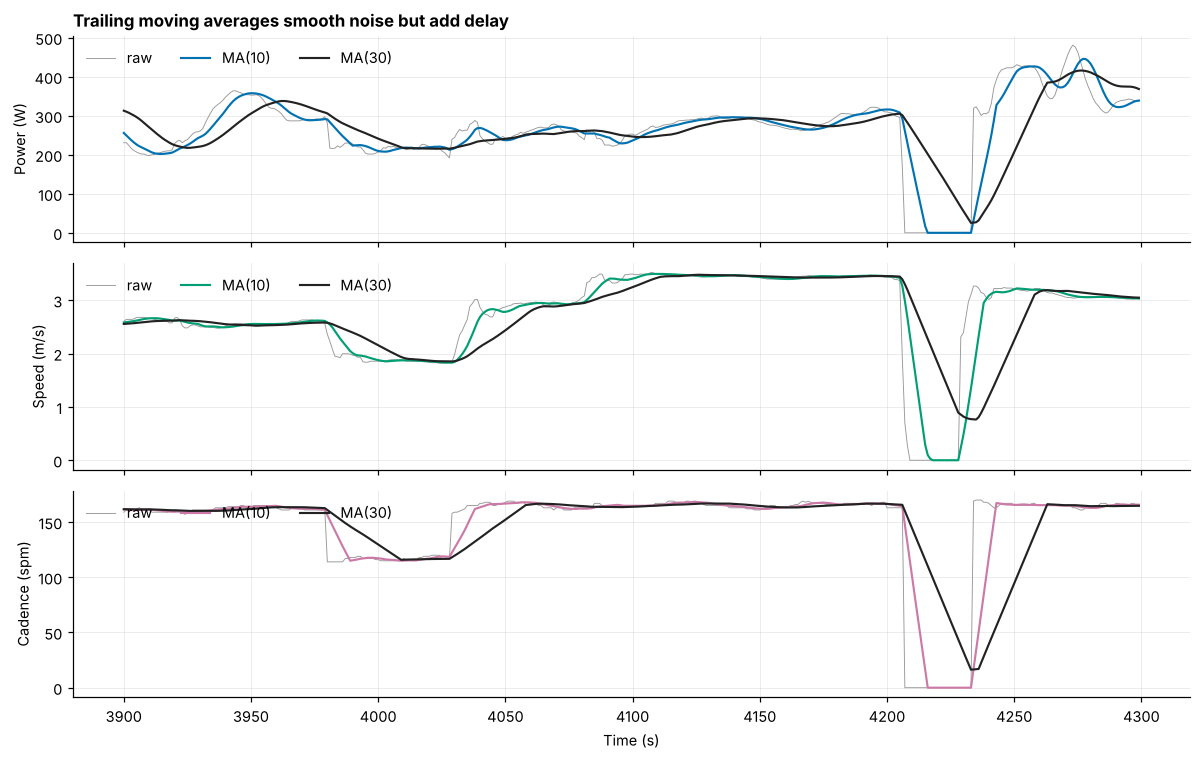

In [15]:
t0, t1 = 3900, 4300
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a, var, ttl in zip(ax, ["power", "speed", "cadence_spm"], ["Power (W)", "Speed (m/s)", "Cadence (spm)"]):
    a.plot(df.index[t0:t1], df[var][t0:t1], color="#999", lw=.6, label="raw")
    for w, c in ((10, COL[var]), (30, "#222")):
        a.plot(df.index[t0:t1], ma(df[var], w)[t0:t1], color=c, lw=1.4, label=f"MA({w})")
    a.set_ylabel(ttl); a.legend(frameon=False, ncol=3, loc="upper left")
ax[-1].set_xlabel("Time (s)"); ax[0].set_title("Trailing moving averages smooth noise but add delay"); fig.tight_layout(); plt.show()

### 3.3 Which smoothing helps explain future HR?
A fast in-sample diagnostic, *not* the final model selection (that happens in the out-of-sample evaluation, step 6).

For each horizon *h* we regress the future change **HR_{t+h} − HR_t** on a compact autoregressive baseline (HR_t and the past changes HR_t − HR_{t−k}, k = 1, 5, 10, 30) and then add one candidate feature at a time. We report the gain in R² (percentage points) over the baseline. Larger = more information about future HR beyond what HR's own history provides.
All candidates share the same sample (t ≥ 60 s) so they are comparable.

In [16]:
BURN = 60
def base_design(hr):
    B = pd.DataFrame({"hr": hr})
    for k in (1, 5, 10, 30): B[f"d{k}"] = hr - hr.shift(k)
    return B

candidates = {}
for var in ["power", "speed", "cadence_spm"]:
    candidates[(var, "raw", 0)] = make_feature(df, var, "raw", 0)
    for kind in ("MA", "EWMA"):
        for w in SMOOTH_W: candidates[(var, kind, w)] = make_feature(df, var, kind, w)
for w in (15, 30, 60): candidates[("grade", "trailing", w)] = df[f"grade{w}"]

B = base_design(df.hr)
rows = []
for h in HORIZONS:
    y = df.hr.shift(-h) - df.hr
    idx = df.index[(df.index >= BURN) & (df.index <= df.index.max() - h)]
    Xb = sm.add_constant(B.loc[idx]); yb = y.loc[idx]
    base = sm.OLS(yb, Xb).fit()
    for (var, kind, w), f in candidates.items():
        x = f.loc[idx]
        if x.isna().any(): x = x.ffill().fillna(x.mean())      # grade is undefined while standing still: carry last value
        m = sm.OLS(yb, Xb.assign(x=x.values)).fit(cov_type="HAC", cov_kwds={"maxlags": h + 10})
        name = f"{var}: raw" if kind == "raw" else f"{var}: {kind}({w})"
        rows.append(dict(var=var, kind=kind, w=w, name=name, h=h, dR2=100 * (m.rsquared - base.rsquared), t=m.tvalues["x"], dBIC=m.bic - base.bic))
R = pd.DataFrame(rows)
tab = R.pivot(index="name", columns="h", values="dR2").loc[R.name.unique()]
display(tab.round(2).style.background_gradient(cmap="Blues", axis=None).format("{:.2f}").set_caption("Gain in R² (percentage points) over AR-only baseline, target = HR(t+h) − HR(t)"))

h,1,5,10,20,30,60,120
name,,,,,,,
power: raw,2.46,8.34,12.55,13.26,9.38,2.16,0.04
power: MA(5),2.00,6.82,10.30,10.61,7.01,1.56,0.00
power: MA(10),1.63,5.56,8.13,7.89,4.68,1.01,0.08
power: MA(30),0.62,1.95,2.53,1.76,0.73,0.10,1.01
power: MA(60),0.20,0.65,0.85,0.70,0.26,0.19,1.81
power: EWMA(5),2.16,7.25,10.88,11.16,7.41,1.66,0.00
power: EWMA(10),1.85,6.23,9.18,8.99,5.53,1.21,0.06
power: EWMA(30),1.10,3.65,5.11,4.44,2.29,0.30,0.71
power: EWMA(60),0.64,2.04,2.70,2.05,0.79,0.00,1.72


,best feature (any variable),ΔR² (pp),HAC t-stat,ΔBIC
horizon h (s),,,,
1,power: raw,2.46,7.75,-132.20
5,power: raw,8.34,7.35,-522.02
10,power: raw,12.55,7.20,-782.80
20,power: raw,13.26,6.06,-812.39
30,power: raw,9.38,4.72,-555.38
60,speed: raw,4.86,2.24,-277.97
120,grade: trailing(60),6.25,-2.50,-383.73


h,1,5,10,20,30,60,120
best smoother per variable,,,,,,,
cadence_spm,cadence_spm: raw,cadence_spm: raw,cadence_spm: raw,cadence_spm: raw,cadence_spm: raw,cadence_spm: raw,cadence_spm: MA(30)
grade,grade: trailing(15),grade: trailing(15),grade: trailing(15),grade: trailing(15),grade: trailing(15),grade: trailing(60),grade: trailing(60)
power,power: raw,power: raw,power: raw,power: raw,power: raw,power: raw,power: MA(60)
speed,speed: raw,speed: raw,speed: raw,speed: raw,speed: raw,speed: raw,speed: EWMA(60)


Negative ΔBIC = adding the feature improves the model even after the complexity penalty.


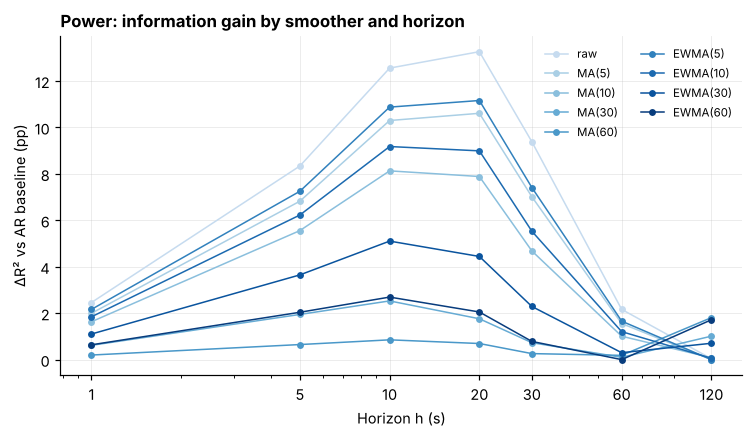

In [17]:
best_all = R.loc[R.groupby("h").dR2.idxmax()].set_index("h")[["name", "dR2", "t", "dBIC"]].round(2)
best_all.columns = ["best feature (any variable)", "ΔR² (pp)", "HAC t-stat", "ΔBIC"]
display(best_all.rename_axis("horizon h (s)"))
best_var = R.loc[R.groupby(["var", "h"]).dR2.idxmax()].pivot(index="var", columns="h", values="name")
display(best_var.rename_axis("best smoother per variable"))
print("Negative ΔBIC = adding the feature improves the model even after the complexity penalty.")

# Power only: gain vs horizon for each smoother
fig, ax = plt.subplots(figsize=(8, 4))
cm = plt.get_cmap("Blues"); names = [n for n in R.name.unique() if n.startswith("power")]
for i, n in enumerate(names):
    r = R[R.name == n]; ax.plot(r.h, r.dR2, marker="o", ms=3.5, color=cm(0.25 + 0.7 * i / (len(names) - 1)), label=n.replace("power: ", ""))
ax.set_xscale("log"); ax.set_xticks(HORIZONS); ax.set_xticklabels(HORIZONS); ax.set_xlabel("Horizon h (s)"); ax.set_ylabel("ΔR² vs AR baseline (pp)")
ax.set_title("Power: information gain by smoother and horizon"); ax.legend(frameon=False, fontsize=7.5, ncol=2); plt.show()

### 3.4 Output of steps 1–3
The feature set and lag estimates that will be carried forward are collected in the next cell. Decisions that remain open are listed in the accompanying discussion.

In [18]:
print("Provisional segment boundaries (s):", SEG_BOUNDS)
print(f"First-order model: best delay d = {d_best} s, τ = {prof.tau[d_best]:.0f} s")
print(f"Distributed-lag step response: 63% at {t63} s, 90% at {t90} s")

Provisional segment boundaries (s): {'warm-up': (0, 600), 'steady': (600, 3900), 'push': (3900, 5100), 'cool-down': (5100, 5313)}
First-order model: best delay d = 0 s, τ = 128 s
Distributed-lag step response: 63% at 51 s, 90% at 84 s


### 3.5 Reading the results (to be discussed before step 4)
**Data (step 1)**
- The file is clean: 5,313 consecutive 1 Hz rows, no gaps or missing values. There are 3 standing-still episodes (43 s in total, 0.8 %) and 8 low-cadence episodes (≈ 5.9 %, likely walking). They are real events, so they are kept, but they create sharp power drops that no model can anticipate.
- Segments differ clearly in mean HR (≈ 140 / 148 / 174 / 169 bpm) and the HR–power relationship is not stable: in the push segment HR sits higher for the same power. This points to cardiac drift or fatigue, and argues for including elapsed time or segment effects later.
- HR in levels is highly persistent (ACF decays very slowly). KPSS rejects stationarity while ADF also rejects a unit root, so the series is slowly varying rather than a clean random walk; ΔHR is stationary. The PACF of HR is dominated by lag 1, and the PACF of ΔHR is significant up to about lag 4.

**Lag structure (step 2)**
- The prewhitened cross-correlation is positive for lags 0–70 s with its peak at about 3–5 s: HR starts to react within seconds, and the reaction spreads out over about a minute.
- The distributed-lag step response reaches 63 % of its final value after ≈ 51 s and 90 % after ≈ 84 s, with a gain of ≈ 0.17 bpm per W (95 % CI 0.11–0.23).
- The first-order model prefers **no pure delay** (best d = 0 s) and gives τ ≈ 128 s and a gain of ≈ 0.36 bpm/W. This disagrees with the distributed-lag estimate. The first-order model works in levels and therefore absorbs the slow drift, while the distributed-lag model works in differences and only captures the short-term dynamics. The two should not be treated as the same quantity. The per-segment estimates are noisy (e.g. the warm-up fit has R² ≈ 0.003 and hits the edge of the delay grid), so I would not interpret them.
- Hypothesis check: "a power change shows up in HR after a delay" is supported, but the delay is short (seconds) and the response is gradual. A distributed lag or a state-space model describes this better than a single lag.

**Smoothing (step 3)**
- All smoothers and grade pass the leakage test.
- For power, **raw power carries the most information up to h = 60 s**; trailing smoothing mostly adds delay. Only at h = 120 s do slow smoothers (MA(60), EWMA(60)) do better than raw, and the gain is small (≈ 1.8 pp).
- The gain from power is largest at h = 10–20 s (≈ 12–13 pp of R²), small at h = 1 s (≈ 2.5 pp), and almost gone by 60 s. This matches the idea that power helps at medium horizons and fades beyond the response time.
- Speed becomes the more useful extra variable at h ≥ 30 s (≈ 4–6 pp). Grade at h = 120 s gives ≈ 6 pp but with a *negative* sign; with a single route this may reflect the hill pattern of this particular run rather than something that generalises.

**Caveats**
- Step 3.3 is an in-sample diagnostic with one coefficient per candidate. A model with several lags of raw power can act as a flexible smoother, so "raw wins" does not mean smoothing is useless in the final ARX; that must be decided out-of-sample (step 6).
- Everything is based on one run.

---
# Part 2 — Models and out-of-sample evaluation (step 4)
*Originally `hr_forecasting_step4_models.ipynb`.*

# Forecasting heart rate from a Garmin run — step 4: models and out-of-sample evaluation
**ISM-E1005 Forecasting Methods in Business Analytics, project work**

This notebook builds the baselines, AR and ARX models and evaluates them out of sample. Findings from steps 1–3 that shape the design:
- HR reacts to power within seconds, and the response spreads over about a minute; power's added information peaks at 10–20 s horizons.
- Raw power and speed were the most informative inputs; grade at 120 s is a risk (route-specific).

**Design (all fixed before looking at forecast errors)**
- **Direct multi-step forecasting:** a separate regression per horizon h ∈ {1, 5, 10, 20, 30, 60, 120} s. Every regressor is observed at the forecast origin *t* or earlier, so no future power is needed at any horizon.
- **Target:** the change HR(t+h) − HR(t). The naive forecast is therefore "change = 0".
- **Rolling origin, expanding window:** forecast origins run from t = 1200 s to the end. Models are refitted every 60 s on all pairs whose *target* is already observed at the refit time (s + h ≤ t_refit). No future information enters training.
- **Fitting:** least squares on standardised features with a very light ridge penalty (λ = 1, negligible with thousands of rows) for numerical stability only. Lag orders are pre-specified (sparse lag sets), not tuned on test errors.
- **Metrics:** RMSE, skill relative to naive (1 − RMSE/RMSE_naive), and Diebold–Mariano tests with HAC standard errors.
- **Segments:** all data is kept, including stops and walking. Segments appear only in evaluation, in the segment-local comparison, and through several alternative boundary sets.

In [19]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox

DATA = "run_2026-04-26.csv"
HORIZONS = [1, 5, 10, 20, 30, 60, 120]
BURN, T_START, STEP = 60, 1200, 60

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "grid.linewidth": .6, "lines.linewidth": 1.5, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5})
df = pd.read_csv(DATA).set_index("t"); N = len(df)
hr = df.hr.astype(float)

## 1. Features (all causal)

In [20]:
def build_features(frame):
    hr = frame.hr.astype(float); pw = frame.power.astype(float); sp = frame.speed.astype(float)
    F = pd.DataFrame(index=frame.index); F["hr"] = hr
    for k in (1, 2, 3, 5, 10, 20, 30, 60): F[f"d{k}"] = hr - hr.shift(k)           # HR momentum: HR_t - HR_{t-k}
    for k in (0, 1, 2, 3, 5, 10, 20, 30, 60): F[f"p{k}"] = pw.shift(k)              # lagged raw power
    for w in (5, 60): F[f"pew{w}"] = pw.ewm(span=w).mean()                           # causal EWMA of power
    F["s0"] = sp; F["sew60"] = sp.ewm(span=60).mean()
    alt = frame.altitude.rolling(5, min_periods=5).mean(); dd = frame.distance - frame.distance.shift(60)
    F["g60"] = (100 * (alt - alt.shift(60)) / dd).where(dd >= 30).clip(-20, 20).ffill().fillna(0)   # trailing 60 s grade
    F["time"] = frame.index.values / 1000                                             # elapsed time (ks), for cardiac drift
    F["m30"] = hr.rolling(30, min_periods=1).mean()                                   # used by the mean-30 baseline
    return F

F = build_features(df)

# Leakage test: corrupt everything after t0 and confirm that no feature at or before t0 changes
rng = np.random.default_rng(1); t0 = 2500
bad = df.astype(float).copy(); m = bad.index > t0
bad.loc[m, :] = bad.loc[m, :].values * rng.uniform(0.5, 1.5, size=(m.sum(), bad.shape[1]))
Fb = build_features(bad)
print("Features are causal (unchanged up to t0 when the future is corrupted):",
      all(np.allclose(F[c][:t0 + 1], Fb[c][:t0 + 1], equal_nan=True) for c in F.columns))
print("Any NaN in features after burn-in:", bool(F.loc[BURN:].isna().any().any()))
Y = {h: (hr.shift(-h) - hr).values for h in HORIZONS}      # targets: HR(t+h) - HR(t)

Features are causal (unchanged up to t0 when the future is corrupted): True
Any NaN in features after burn-in: False


## 2. Models
Every model predicts the change HR(t+h) − HR(t). The HR block is the same in all AR/ARX models, so differences between them are due to the extra inputs only.

| Model | Regressors |
|---|---|
| naive | change = 0 (last value) |
| mean30 | forecast = mean of the last 30 s of HR |
| drift30 | continues the last 30 s slope for h seconds |
| AR-small | HR level and HR_t − HR_{t−k}, k = 1, 5, 10, 30 |
| AR-large | HR level and HR_t − HR_{t−k}, k = 1, 2, 3, 5, 10, 20, 30, 60 |
| ARX-compact | AR-small + raw power, EWMA(5) and EWMA(60) of power |
| ARX-power-lags | AR-large + power at lags 0, 1, 2, 3, 5, 10, 20, 30, 60 |
| ARX-power-smooth | AR-large + raw power, EWMA(5), EWMA(60) |
| ARX+speed | ARX-power-smooth + raw speed and EWMA(60) of speed |
| ARX+speed+grade | ARX+speed + trailing 60 s grade |
| ARX+speed+grade+time | ARX+speed+grade + elapsed time (linear cardiac drift) |

In [21]:
HR_SMALL = ["hr", "d1", "d5", "d10", "d30"]
HR_LARGE = ["hr", "d1", "d2", "d3", "d5", "d10", "d20", "d30", "d60"]
P_LAGS = [f"p{k}" for k in (0, 1, 2, 3, 5, 10, 20, 30, 60)]
P_SMOOTH = ["p0", "pew5", "pew60"]
MODELS = {
    "AR-small": HR_SMALL,
    "AR-large": HR_LARGE,
    "ARX-compact": HR_SMALL + P_SMOOTH,
    "ARX-power-lags": HR_LARGE + P_LAGS,
    "ARX-power-smooth": HR_LARGE + P_SMOOTH,
    "ARX+speed": HR_LARGE + P_SMOOTH + ["s0", "sew60"],
    "ARX+speed+grade": HR_LARGE + P_SMOOTH + ["s0", "sew60", "g60"],
    "ARX+speed+grade+time": HR_LARGE + P_SMOOTH + ["s0", "sew60", "g60", "time"],
}
BASELINES = ["naive", "mean30", "drift30"]

def fit_ridge(X, y, lam=1.0):
    mu, sd = X.mean(0), X.std(0) + 1e-9; Z = (X - mu) / sd; ym = y.mean()
    b = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ (y - ym))
    return mu, sd, b, ym
def predict_ridge(model, X): mu, sd, b, ym = model; return ((X - mu) / sd) @ b + ym

def rolling_preds(cols, h, lo, hi, train_from=None, step=STEP, window=None):
    """Predicted changes for origins lo..hi-1. Refit every `step` s on pairs (s, s+h) with s+h <= refit time."""
    X, y = F[cols].values, Y[h]; tf = BURN if train_from is None else max(train_from, BURN)
    out = np.full(hi - lo, np.nan)
    for tb in range(lo, hi, step):
        t_lo = tf if window is None else max(tf, tb - h - window + 1)
        tr = np.arange(t_lo, tb - h + 1); te = np.arange(tb, min(tb + step, hi))
        out[te - lo] = predict_ridge(fit_ridge(X[tr], y[tr]), X[te])
    return out

## 3. Rolling-origin evaluation

In [22]:
ERR = {}                                                   # horizon -> DataFrame of forecast errors (HR units), indexed by origin
for h in HORIZONS:
    lo, hi = T_START, N - h; y = Y[h][lo:hi]
    E = {"naive": y, "mean30": y - (F.m30.values - F.hr.values)[lo:hi], "drift30": y - (h * F.d30.values / 30)[lo:hi]}
    for name, cols in MODELS.items(): E[name] = y - rolling_preds(cols, h, lo, hi)
    ERR[h] = pd.DataFrame(E, index=np.arange(lo, hi))
ORDER = BASELINES + list(MODELS)
RMSE = pd.DataFrame({h: np.sqrt((ERR[h] ** 2).mean()) for h in HORIZONS}).loc[ORDER]
MAE = pd.DataFrame({h: ERR[h].abs().mean() for h in HORIZONS}).loc[ORDER]
print("Origins per horizon:", {h: len(ERR[h]) for h in HORIZONS}); print("Any NaN in errors:", any(ERR[h].isna().any().any() for h in HORIZONS))
display(RMSE.round(2).rename_axis("RMSE (bpm)").style.format("{:.2f}").background_gradient(cmap="Blues", axis=0))

Origins per horizon: {1: 4112, 5: 4108, 10: 4103, 20: 4093, 30: 4083, 60: 4053, 120: 3993}
Any NaN in errors: False


,1,5,10,20,30,60,120
RMSE (bpm),,,,,,,
naive,0.60,1.61,2.66,4.14,5.15,6.72,8.43
mean30,3.00,3.56,4.15,5.05,5.69,7.06,8.45
drift30,0.61,1.77,3.15,5.61,7.76,13.02,23.77
AR-small,0.58,1.53,2.60,4.17,5.25,6.95,9.32
AR-large,0.58,1.52,2.59,4.18,5.26,6.96,9.36
ARX-compact,0.58,1.47,2.45,3.95,5.04,6.93,9.46
ARX-power-lags,0.58,1.47,2.48,4.00,5.07,6.93,9.48
ARX-power-smooth,0.57,1.46,2.45,3.96,5.06,6.95,9.53
ARX+speed,0.58,1.49,2.54,4.08,5.07,6.91,9.30


In [23]:
def dm(e_a, e_b, h):
    d = e_a ** 2 - e_b ** 2                                                # negative mean => model A better
    f = sm.OLS(d.values, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": h + 10})
    return f.params[0], f.pvalues[0]

SKILL = 100 * (1 - RMSE / RMSE.loc["naive"])
star = lambda p: "*" if p < 0.05 else ""
tab = pd.DataFrame({h: {m: f"{SKILL.loc[m, h]:.1f}{star(dm(ERR[h][m], ERR[h]['naive'], h)[1])}" for m in ORDER[1:]} for h in HORIZONS})
display(tab.rename_axis("skill vs naive (%)").style.set_caption("100·(1 − RMSE/RMSE_naive); * = Diebold–Mariano p < 0.05 vs naive (HAC)"))

ARX = [m for m in MODELS if m.startswith("ARX")]
GAIN = 100 * (1 - RMSE.loc[ARX] / RMSE.loc["AR-large"])
tab2 = pd.DataFrame({h: {m: f"{GAIN.loc[m, h]:.1f}{star(dm(ERR[h][m], ERR[h]['AR-large'], h)[1])}" for m in ARX} for h in HORIZONS})
display(tab2.rename_axis("gain over AR-large (%)").style.set_caption("100·(1 − RMSE/RMSE_AR-large); positive = better than AR-large; * = DM p < 0.05"))

,1,5,10,20,30,60,120
skill vs naive (%),,,,,,,
mean30,-399.9*,-120.2*,-56.0*,-22.0*,-10.6*,-5.1,-0.2
drift30,-1.8*,-9.4*,-18.5*,-35.5*,-50.8*,-93.7*,-181.9*
AR-small,2.7*,5.4*,2.5,-0.7,-1.9,-3.3,-10.6
AR-large,3.1*,6.1*,2.7,-0.8,-2.1,-3.5,-11.0
ARX-compact,3.9*,9.0*,7.9*,4.7,2.1,-3.1,-12.1
ARX-power-lags,3.9*,8.7*,6.7,3.3,1.5,-3.1,-12.5
ARX-power-smooth,4.2*,9.6*,8.0*,4.5,1.7,-3.3,-13.0
ARX+speed,3.8*,7.6*,4.6,1.4,1.5,-2.7,-10.3
ARX+speed+grade,3.8*,7.9*,5.4,2.6,2.1,-3.3,-10.7


,1,5,10,20,30,60,120
gain over AR-large (%),,,,,,,
ARX-compact,0.8*,3.1,5.3*,5.5,4.2,0.4,-1.0
ARX-power-lags,0.8*,2.8,4.1,4.1,3.5,0.4,-1.3
ARX-power-smooth,1.1*,3.7*,5.4*,5.3,3.8,0.2,-1.8
ARX+speed,0.7,1.5,1.9,2.2,3.6,0.7,0.6
ARX+speed+grade,0.8,1.8,2.7,3.4,4.2,0.2,0.3
ARX+speed+grade+time,0.6,1.0,1.6,2.4,3.1,-1.6,-2.1


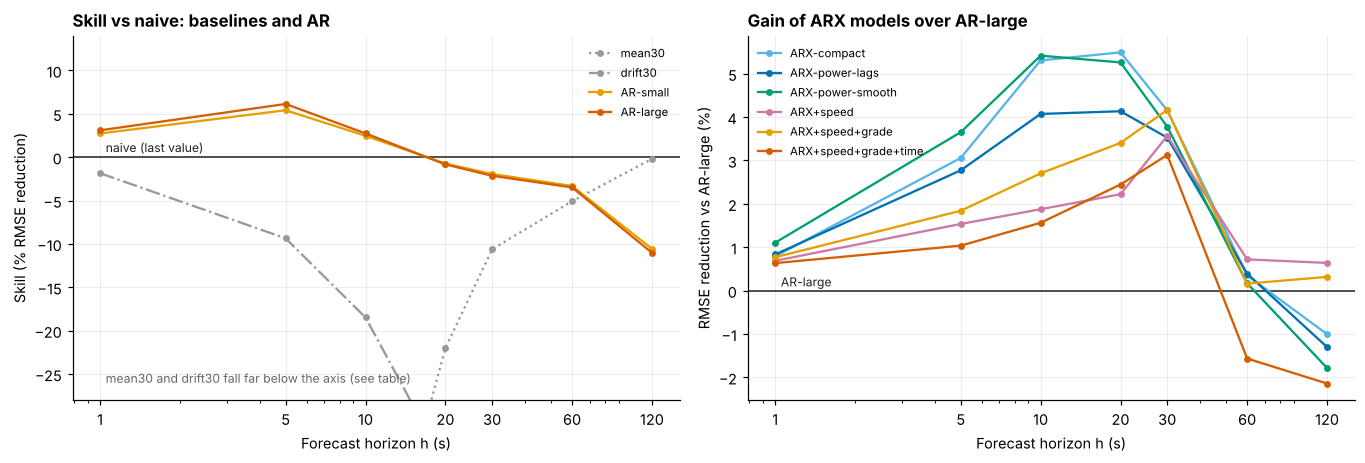

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
x = HORIZONS
ax[0].axhline(0, color="#222", lw=1); ax[0].text(1.05, 0.6, "naive (last value)", fontsize=8, color="#222")
for m, c, ls in (("mean30", "#999999", ":"), ("drift30", "#999999", "-."), ("AR-small", "#E69F00", "-"), ("AR-large", "#D55E00", "-")):
    ax[0].plot(x, SKILL.loc[m], color=c, ls=ls, marker="o", ms=3.5, label=m)
ax[0].set_ylim(-28, 14); ax[0].text(1.05, -26, "mean30 and drift30 fall far below the axis (see table)", fontsize=8, color="#666")
ax[0].set_title("Skill vs naive: baselines and AR"); ax[0].set_ylabel("Skill (% RMSE reduction)")
cols = {"ARX-compact": "#56B4E9", "ARX-power-lags": "#0072B2", "ARX-power-smooth": "#009E73", "ARX+speed": "#CC79A7", "ARX+speed+grade": "#E69F00", "ARX+speed+grade+time": "#D55E00"}
ax[1].axhline(0, color="#222", lw=1); ax[1].text(1.05, 0.1, "AR-large", fontsize=8, color="#222")
for m, c in cols.items(): ax[1].plot(x, GAIN.loc[m], color=c, marker="o", ms=3.5, label=m)
ax[1].set_title("Gain of ARX models over AR-large"); ax[1].set_ylabel("RMSE reduction vs AR-large (%)")
for a in ax: a.set_xscale("log"); a.set_xticks(x); a.set_xticklabels(x); a.set_xlabel("Forecast horizon h (s)"); a.legend(frameon=False, fontsize=7.5)
fig.tight_layout(); plt.show()

### 3.1 Residual check (1-step forecasts)
For h = 1 the direct forecast errors should be close to white noise if the model has captured the dynamics. (For h > 1 overlapping errors are autocorrelated by construction, so the test only makes sense at h = 1.)

In [25]:
rows = []
for m in ("naive", "AR-large", "ARX-power-smooth", "ARX+speed"):
    lb = acorr_ljungbox(ERR[1][m], lags=[10, 30], return_df=True)
    rows.append({"model": m, "LB p (10 lags)": lb.lb_pvalue.iloc[0], "LB p (30 lags)": lb.lb_pvalue.iloc[1], "lag-1 autocorr": ERR[1][m].autocorr(1)})
display(pd.DataFrame(rows).set_index("model").round(4))

,LB p (10 lags),LB p (30 lags),lag-1 autocorr
model,,,
naive,0.0,0.0,0.0311
AR-large,0.0,0.0,-0.0804
ARX-power-smooth,0.0,0.0,-0.0851
ARX+speed,0.0,0.0,-0.0714


## 4. Where do the models work? Errors by segment
Origins are assigned to the provisional segments from step 1 (warm-up is mostly excluded because evaluation starts at 1200 s). This is purely a breakdown of the same forecasts, so no model is refitted. Blue = better, red = worse.

In [26]:
B1 = {"warm-up": (0, 600), "steady": (600, 3900), "push": (3900, 5100), "cool-down": (5100, 99999)}
def seg_of(t, B): return next(k for k, (a, b) in B.items() if a <= t < b)
def seg_table(h, ref, B=B1):
    s = pd.Series([seg_of(t, B) for t in ERR[h].index], index=ERR[h].index)
    r = {g: np.sqrt((ERR[h][s == g] ** 2).mean()) for g in B if (s == g).sum() > 30}
    r = pd.DataFrame(r); return 100 * (1 - r.div(r.loc[ref]))
for ref, title in (("naive", "Skill vs naive (%) by segment"), ("AR-large", "Gain over AR-large (%) by segment")):
    T = pd.concat({f"h={h}": seg_table(h, ref) for h in (5, 10, 30, 60)}, axis=1)
    T = T.drop(index=BASELINES[:1] if ref == "naive" else ["naive", "mean30", "drift30", "AR-large"], errors="ignore")
    display(T.round(1).style.background_gradient(cmap="RdBu", vmin=-25, vmax=25, axis=None).format("{:.1f}").set_caption(title))
print("Origins per segment:", pd.Series([seg_of(t, B1) for t in ERR[10].index]).value_counts().to_dict())

Origins per segment: {'steady': 2700, 'push': 1200, 'cool-down': 203}


## 5. With and without segments
A model with segment-specific coefficients needs training data from the segment it forecasts. In a single run with an expanding window this is impossible at the start of a segment (the push is not yet seen when it begins), so the following comparison uses a fair version:

- **Segment-local model:** for an origin that is at least 300 s into a segment, train only on data from that same segment (so far).
- **Global model:** the same model trained on everything observed so far.

Both are evaluated on exactly the same origins. The segment boundaries are arbitrary, so three alternative boundary sets are used. A ratio below 1 means that the segment-local model is better.

In [27]:
SETS = {"B1": (600, 3900, 5100), "B2": (300, 3700, 4900), "B3": (900, 4200, 5300)}
MIN_ELAPSED = 300
def rmse(e): return float(np.sqrt(np.mean(e ** 2)))
rows = []
for sname, (a, b, c) in SETS.items():
    for seg, (s0, s1) in {"steady": (a, b), "push": (b, c)}.items():
        for h in HORIZONS:
            lo, hi = s0 + MIN_ELAPSED, min(s1, N - h)
            if hi - lo < 60: continue
            y = Y[h][lo:hi]; r = dict(set=sname, segment=seg, h=h, n=hi - lo)
            for m in ("AR-small", "ARX-compact"):
                r[f"{m} global"] = rmse(y - rolling_preds(MODELS[m], h, lo, hi))
                r[f"{m} local"] = rmse(y - rolling_preds(MODELS[m], h, lo, hi, train_from=s0))
            r["naive"] = rmse(y); rows.append(r)
L = pd.DataFrame(rows)
L["AR local/global"] = L["AR-small local"] / L["AR-small global"]
L["ARX local/global"] = L["ARX-compact local"] / L["ARX-compact global"]
L["ARX gain vs AR, global (%)"] = 100 * (1 - L["ARX-compact global"] / L["AR-small global"])
L["ARX gain vs AR, local (%)"] = 100 * (1 - L["ARX-compact local"] / L["AR-small local"])
for col, ttl, kw in (("AR local/global", "RMSE ratio local/global, AR-small (<1: local better)", dict(cmap="RdBu_r", vmin=.7, vmax=1.3)),
                     ("ARX local/global", "RMSE ratio local/global, ARX-compact (<1: local better)", dict(cmap="RdBu_r", vmin=.7, vmax=1.3)),
                     ("ARX gain vs AR, global (%)", "ARX-compact gain over AR-small, global fit (%)", dict(cmap="RdBu", vmin=-15, vmax=15)),
                     ("ARX gain vs AR, local (%)", "ARX-compact gain over AR-small, segment-local fit (%)", dict(cmap="RdBu", vmin=-15, vmax=15))):
    P = L.pivot_table(index=["set", "segment"], columns="h", values=col)
    display(P.round(2).style.background_gradient(axis=None, **kw).format("{:.2f}").set_caption(ttl))
print("Origins per cell (n):"); display(L.pivot_table(index=["set", "segment"], columns="h", values="n").astype(int))

Origins per cell (n):


h             1     5     10    20    30    60    120
set segment                                          
B1  push      900   900   900   900   900   900   900
    steady   3000  3000  3000  3000  3000  3000  3000
B2  push      900   900   900   900   900   900   900
    steady   3100  3100  3100  3100  3100  3100  3100
B3  push      800   800   800   793   783   753   693
    steady   3000  3000  3000  3000  3000  3000  3000

## 6. Errors around stops
Stops (speed < 0.3 m/s with zero power) are unpredictable from HR history, and power drops to zero. The table compares RMSE for forecast *targets* falling in a stop or within 30 s after it with all other targets. No data are removed.

In [28]:
stopped = (df.speed < 0.3) & (df.power == 0); mm = stopped.values.astype(int); d = np.diff(np.r_[0, mm, 0])
runs = [(s, e) for s, e in zip(np.where(d == 1)[0], np.where(d == -1)[0]) if e - s >= 3]
print("Stop episodes (start, length s):", [(int(df.index[s]), e - s) for s, e in runs])
in_win = np.zeros(N, bool)
for s, e in runs: in_win[s:min(e + 30, N)] = True
rows = []
for h in (10, 30):
    tgt = ERR[h].index.values + h; w = in_win[tgt]
    for m in ("naive", "AR-large", "ARX-power-smooth", "ARX+speed"):
        rows.append({"h": h, "model": m, "RMSE in stop windows": rmse(ERR[h][m][w]), "RMSE elsewhere": rmse(ERR[h][m][~w]), "n windows/other": f"{w.sum()}/{(~w).sum()}"})
display(pd.DataFrame(rows).set_index(["h", "model"]).round(2))

Stop episodes (start, length s): [(2127, np.int64(15)), (3343, np.int64(7)), (4208, np.int64(21))]


RMSE in stop windows  RMSE elsewhere n windows/other
h  model                                                                 
10 naive                             5.44            2.52        133/3970
   AR-large                          4.81            2.48        133/3970
   ARX-power-smooth                  4.80            2.33        133/3970
   ARX+speed                         6.71            2.27        133/3970
30 naive                             8.37            5.00        133/3950
   AR-large                          6.82            5.20        133/3950
   ARX-power-smooth                  8.10            4.92        133/3950
   ARX+speed                         9.14            4.88        133/3950

## 7. Example forecasts (h = 30 s)

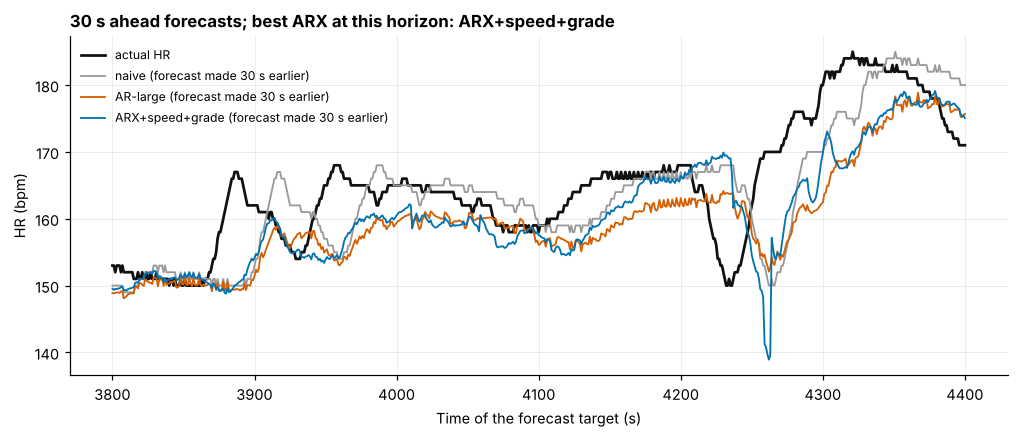

Best ARX model by RMSE at each horizon: {1: 'ARX-power-smooth', 5: 'ARX-power-smooth', 10: 'ARX-power-smooth', 20: 'ARX-compact', 30: 'ARX+speed+grade', 60: 'ARX+speed', 120: 'ARX+speed'}


In [29]:
h = 30; best = RMSE[h].loc[ARX].idxmin(); t0, t1 = 3800, 4400
cols = {"naive": "#999999", "AR-large": "#D55E00", best: "#0072B2"}
fig, ax = plt.subplots(figsize=(11, 4)); idx = ERR[h].index[(ERR[h].index + h >= t0) & (ERR[h].index + h <= t1)]
ax.plot(idx + h, hr.values[idx + h], color="#111", lw=1.8, label="actual HR")
for m, c in cols.items(): ax.plot(idx + h, hr.values[idx + h] - ERR[h].loc[idx, m].values, color=c, lw=1.2, label=f"{m} (forecast made 30 s earlier)")
ax.set_xlabel("Time of the forecast target (s)"); ax.set_ylabel("HR (bpm)"); ax.set_title(f"30 s ahead forecasts; best ARX at this horizon: {best}"); ax.legend(frameon=False, fontsize=8)
plt.show()
print("Best ARX model by RMSE at each horizon:", RMSE.loc[ARX].idxmin().to_dict())

## 8. Post-hoc diagnostic: why do the models lose to naive beyond ~20 s?
**This section is not part of the pre-specified model list.** It was added after seeing the results above, to test one explanation: the HR *level* term pulls forecasts toward the HR levels seen in training (the steady stretch, ≈ 145–160 bpm), which is wrong once the push has lifted HR to 170–185 bpm, and the long expanding window adapts slowly to that shift. Two variants test this:
- **no level:** the same models with the HR level removed, so only momentum and power enter;
- **window 900 s:** the same models with the level, but trained only on the most recent 900 s of pairs.

Because these variants were chosen after looking at the test errors, treat any improvement as a hypothesis to confirm, not as a clean out-of-sample result.

In [30]:
def drop_level(cols): return [c for c in cols if c != "hr"]
DIAG = {"AR-large (no level)": ("AR-large", dict(drop=True)), "ARX-compact (no level)": ("ARX-compact", dict(drop=True)),
        "ARX-power-smooth (no level)": ("ARX-power-smooth", dict(drop=True)),
        "AR-large (window 900 s)": ("AR-large", dict(window=900)), "ARX-power-smooth (window 900 s)": ("ARX-power-smooth", dict(window=900))}
DERR = {}
for h in HORIZONS:
    lo, hi = T_START, N - h; y = Y[h][lo:hi]; E = {}
    for name, (base, kw) in DIAG.items():
        cols = drop_level(MODELS[base]) if kw.get("drop") else MODELS[base]
        E[name] = y - rolling_preds(cols, h, lo, hi, window=kw.get("window"))
    DERR[h] = pd.DataFrame(E, index=np.arange(lo, hi))
REF = ["naive", "AR-large", "ARX-power-smooth"]
DR = pd.DataFrame({h: pd.concat([np.sqrt((ERR[h][REF] ** 2).mean()), np.sqrt((DERR[h] ** 2).mean())]) for h in HORIZONS})
display(DR.round(2).style.format("{:.2f}").set_caption("RMSE (bpm): reference models and post-hoc variants"))
DS = 100 * (1 - DR / DR.loc["naive"])
tabd = pd.DataFrame({h: {m: f"{DS.loc[m, h]:.1f}{star(dm((ERR[h] if m in REF else DERR[h])[m], ERR[h]['naive'], h)[1])}" for m in DS.index if m != "naive"} for h in HORIZONS})
display(tabd.style.set_caption("Skill vs naive (%), * = DM p < 0.05"))

# By segment (B1) for the push, where the problem is largest
allerr = {h: pd.concat([ERR[h][REF], DERR[h]], axis=1) for h in HORIZONS}
rows = {}
for h in (10, 30, 60):
    s_ = pd.Series([seg_of(t, B1) for t in allerr[h].index], index=allerr[h].index)
    for g in ("steady", "push"):
        r = np.sqrt((allerr[h][s_ == g] ** 2).mean()); rows[(f"h={h}", g)] = 100 * (1 - r / r["naive"])
display(pd.DataFrame(rows).drop(index="naive").round(1).style.background_gradient(cmap="RdBu", vmin=-25, vmax=25, axis=None).format("{:.1f}").set_caption("Skill vs naive (%) by segment"))

,1,5,10,20,30,60,120
naive,0.60,1.61,2.66,4.14,5.15,6.72,8.43
AR-large,0.58,1.52,2.59,4.18,5.26,6.96,9.36
ARX-power-smooth,0.57,1.46,2.45,3.96,5.06,6.95,9.53
AR-large (no level),0.58,1.51,2.56,4.11,5.16,6.73,8.45
ARX-compact (no level),0.58,1.47,2.44,3.90,4.94,6.65,8.73
ARX-power-smooth (no level),0.57,1.46,2.44,3.93,4.99,6.69,8.84
AR-large (window 900 s),0.58,1.52,2.59,4.24,5.40,7.19,8.96
ARX-power-smooth (window 900 s),0.58,1.49,2.53,4.19,5.43,7.59,9.32


,1,5,10,20,30,60,120
AR-large,3.1*,6.1*,2.7,-0.8,-2.1,-3.5,-11.0
ARX-power-smooth,4.2*,9.6*,8.0*,4.5,1.7,-3.3,-13.0
AR-large (no level),3.2*,6.6*,3.7,0.8,-0.2,-0.1,-0.2
ARX-compact (no level),3.8*,9.1*,8.4*,5.9,4.1,1.0,-3.6
ARX-power-smooth (no level),4.1*,9.6*,8.2*,5.2,3.0,0.4,-4.8
AR-large (window 900 s),2.9*,6.1*,2.8,-2.4,-5.0,-7.0,-6.3
ARX-power-smooth (window 900 s),3.8*,7.6*,4.9,-1.1,-5.6,-12.8,-10.5


## 9. Reading the results
**Pre-specified models (sections 3–7)**
- **Naive is hard to beat.** At h = 1 s the best model (ARX-power-smooth) lowers RMSE from 0.60 to 0.57 bpm (4 %); at 5 s from 1.61 to 1.46 (≈ 10 %); at 10 s the gain is ≈ 8 %. These are significant (DM, HAC). At 20–30 s the gain is small and not significant, and from 60 s on every pre-specified model is worse than naive.
- **Power helps, in the window the physiology predicts.** Over AR-large, power lowers RMSE by about 1 % at 1 s, 4 % at 5 s, and 5 % at 10–20 s (significant at 1–10 s for ARX-power-smooth). The gain disappears by 60 s and turns negative at 120 s.
- **More inputs do not help.** Speed, grade and elapsed time give no gain over the compact power models at short horizons; ARX-compact (fewest parameters) is as good as the larger ones. There is no sign that speed or grade rescues the long horizons.
- **Where the gain sits.** The ARX advantage over AR is concentrated in the push (≈ 10–13 % at h = 5–10) and the cool-down (≈ 12–18 %, but only 203 origins). In the steady stretch it is ≈ 0–2 % at h ≤ 10.
- **Segment-specific models** are not reliably better than a global model. Local/global RMSE ratios are mostly 1.0–1.3 (global better), with exceptions that depend on the boundary set (for example the push under B2). There is no robust evidence for segment-specific fitting, which fits the view that the segmentation is arbitrary.
- **Stops** roughly double the errors around them (h = 10: naive 5.4 vs 2.5 bpm), and ARX+speed does worse than AR there, because speed goes to zero. This rests on only three stop episodes.
- **Residuals** are not white at h = 1 (Ljung–Box rejects for every model, including naive), but the lag-1 autocorrelation is small (|r| ≤ 0.09). HR is integer-valued and ΔHR has some structure up to about 4 s, so some short-lag structure is left; its size is small.

**Why the long horizons fail, and the post-hoc diagnostic (section 8)**
- The forecast plot shows that AR and ARX forecasts sag toward the steady-state HR while actual HR keeps climbing in the push. Removing the HR *level* term fixes most of this: ARX-compact (no level) beats naive by 3.8 %, 9.1 %, 8.4 %, 5.9 %, 4.1 % and 1.0 % at h = 1, 5, 10, 20, 30 and 60 s, and loses only at 120 s (−3.6 %). A shorter training window (900 s) does not help, so slow adaptation alone is not the explanation.
- The level term does help *within* the steady stretch (skill 7–12 % at 30–60 s): HR there really does revert toward its plateau. That mean reversion simply does not carry over to the push, where HR sits at a different level for the same power.
- These variants were chosen after seeing the errors, so they should be read as a hypothesis that needs confirming, not as a clean out-of-sample result.

**Caveats**
- One run, one person. The test period contains one long steady stretch and one push, so results at long horizons depend heavily on how the push behaves.
- In absolute terms the improvements are small (a few tenths of a bpm at short horizons).
- The ridge penalty and lag sets were fixed in advance, but model choice among about ten candidates on one test run still carries some selection risk.

---
# Part 3 — Robustness of the main result (step 5a)
*Originally `hr_forecasting_step5a_robustness.ipynb`.*

# Forecasting heart rate from a Garmin run — step 5a: robustness of the main result
**ISM-E1005 Forecasting Methods in Business Analytics, project work**

Step 4 ended with a post-hoc finding: removing the HR *level* term stops the models from losing to naive at long horizons. Only one run is available, so the question here is how far that result can be trusted *within* this run.

**Frozen specification.** The no-level model family below is fixed before any of the checks in this notebook and is not changed afterwards. It was selected after seeing the step-4 test errors, so it is **exploratory**, not a clean out-of-sample result.

| Model | Regressors (all causal) |
|---|---|
| AR (no level) | HR momentum HR_t − HR_{t−k}, k = 1, 2, 3, 5, 10, 20, 30, 60 |
| **ARX-compact (no level)** — main model | momentum k = 1, 5, 10, 30; raw power, EWMA(5) and EWMA(60) of power |
| ARX-smooth (no level) | AR (no level) momentum + the same three power inputs |
| ARX+speed (no level) | ARX-smooth + raw speed and EWMA(60) of speed |
| AR-large (level), ARX-smooth (level) | the step-4 versions with the HR level, shown for contrast |

**Checks**
1. Reproduce the step-4 numbers for these models.
2. Block-bootstrap confidence intervals for skill (errors are strongly autocorrelated, so ordinary standard errors would be too optimistic).
3. Stability across three consecutive time blocks of the run.
4. Sensitivity to the design choices that were made by hand (refit interval, evaluation start, ridge strength, momentum lags, EWMA spans).

In [31]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import hrlib as H

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "grid.linewidth": .6, "lines.linewidth": 1.5, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5})
HOR = H.HORIZONS; T_START, STEP = 1200, 60
df = H.load(); N = len(df); hr = df.hr.astype(float)
F = H.build_features(df); Y = H.targets(hr)

MOM_S, MOM_L, EW = (1, 5, 10, 30), (1, 2, 3, 5, 10, 20, 30, 60), (5, 60)
FROZEN = {
    "AR (no level)": H.spec(MOM_L),
    "ARX-compact (no level)": H.spec(MOM_S, EW),
    "ARX-smooth (no level)": H.spec(MOM_L, EW),
    "ARX+speed (no level)": H.spec(MOM_L, EW, speed=True),
    "AR-large (level)": H.spec(MOM_L, level=True),
    "ARX-smooth (level)": H.spec(MOM_L, EW, level=True),
}
MAIN = "ARX-compact (no level)"; REF = "AR (no level)"

## 1. Reproduction of the step-4 numbers

In [32]:
ERR = {}
for h in HOR:
    lo, hi = T_START, N - h; y = Y[h][lo:hi]
    E = {"naive": y}
    for name, cols in FROZEN.items(): E[name] = y - H.rolling_preds(F, Y, cols, h, lo, hi, step=STEP)
    ERR[h] = pd.DataFrame(E, index=np.arange(lo, hi))
RMSE = pd.DataFrame({h: np.sqrt((ERR[h] ** 2).mean()) for h in HOR})
SKILL = 100 * (1 - RMSE / RMSE.loc["naive"])
display(RMSE.round(2).style.format("{:.2f}").set_caption("RMSE (bpm)"))
display(SKILL.drop(index="naive").round(1).style.format("{:.1f}").set_caption("Skill vs naive (%)"))
print("Step-4 reference for ARX-compact (no level): 3.8 / 9.1 / 8.4 / 5.9 / 4.1 / 1.0 / -3.6 %")

,1,5,10,20,30,60,120
naive,0.60,1.61,2.66,4.14,5.15,6.72,8.43
AR (no level),0.58,1.51,2.56,4.11,5.16,6.73,8.45
ARX-compact (no level),0.58,1.47,2.44,3.90,4.94,6.65,8.73
ARX-smooth (no level),0.57,1.46,2.44,3.93,4.99,6.69,8.84
ARX+speed (no level),0.58,1.49,2.53,4.11,5.13,6.89,9.04
AR-large (level),0.58,1.52,2.59,4.18,5.26,6.96,9.36
ARX-smooth (level),0.57,1.46,2.45,3.96,5.06,6.95,9.53


,1,5,10,20,30,60,120
AR (no level),3.2,6.6,3.7,0.8,-0.2,-0.1,-0.2
ARX-compact (no level),3.8,9.1,8.4,5.9,4.1,1.0,-3.6
ARX-smooth (no level),4.1,9.6,8.2,5.2,3.0,0.4,-4.8
ARX+speed (no level),3.8,7.9,4.9,0.7,0.3,-2.5,-7.2
AR-large (level),3.1,6.1,2.7,-0.8,-2.1,-3.5,-11.0
ARX-smooth (level),4.2,9.6,8.0,4.5,1.7,-3.3,-13.0


Step-4 reference for ARX-compact (no level): 3.8 / 9.1 / 8.4 / 5.9 / 4.1 / 1.0 / -3.6 %


## 2. Block-bootstrap confidence intervals
Circular moving-block bootstrap of the squared forecast errors (block length 200 s, 2,000 resamples). The same resampled blocks are used for all models, so differences between models keep their pairing. Intervals are 95 % percentile intervals.

,ARX-compact (no level): skill vs naive (%),AR (no level): skill vs naive (%),ARX-compact (no level): gain over AR (no level) (%)
h (s),,,
1,"3.8 [1.7, 5.9]","3.2 [1.6, 4.7]","0.6 [-0.3, 1.6]"
5,"9.1 [2.4, 15.6]","6.6 [3.1, 9.7]","2.7 [-1.5, 7.1]"
10,"8.4 [0.3, 15.9]","3.7 [0.3, 6.4]","4.9 [-1.5, 11.5]"
20,"5.9 [-2.4, 13.1]","0.8 [-3.3, 3.9]","5.2 [-1.7, 11.5]"
30,"4.1 [-2.9, 9.5]","-0.2 [-4.8, 3.8]","4.2 [-1.7, 9.0]"
60,"1.0 [-5.8, 6.8]","-0.1 [-5.6, 4.3]","1.1 [-5.8, 7.1]"
120,"-3.6 [-18.7, 7.7]","-0.2 [-6.3, 6.8]","-3.3 [-19.1, 8.5]"


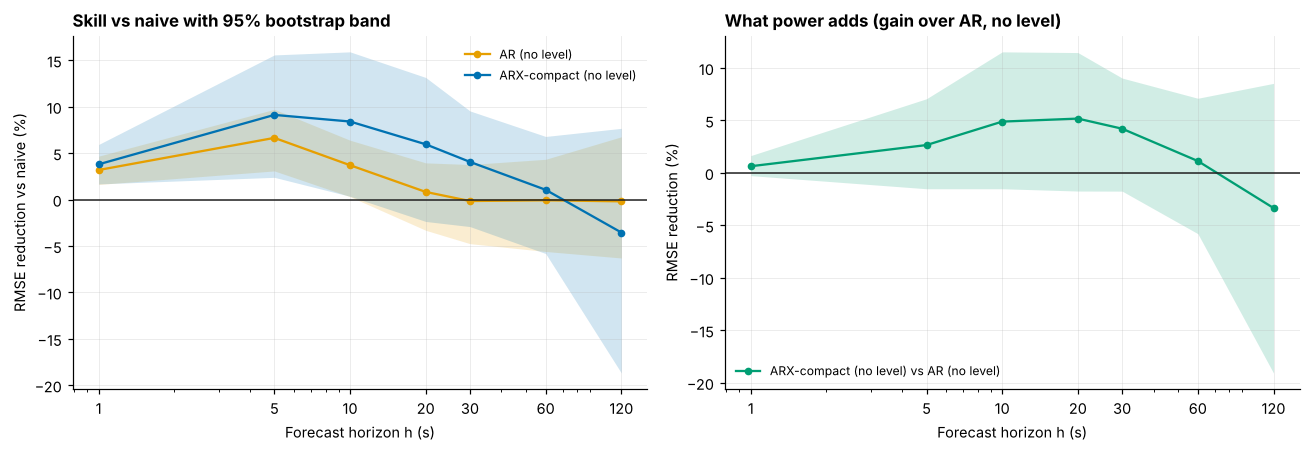

In [33]:
L_BLOCK, B = 200, 2000
rows = []
for h in HOR:
    e2 = [ERR[h]["naive"].values ** 2, ERR[h][MAIN].values ** 2, ERR[h][REF].values ** 2]
    bs = np.sqrt(H.block_boot(e2, L=L_BLOCK, B=B, seed=h))
    s_main = 100 * (1 - bs[:, 1] / bs[:, 0]); s_ref = 100 * (1 - bs[:, 2] / bs[:, 0]); gain = 100 * (1 - bs[:, 1] / bs[:, 2])
    pt = lambda m: 100 * (1 - RMSE.loc[m, h] / RMSE.loc["naive", h])
    rows.append(dict(h=h, main=pt(MAIN), main_lo=np.percentile(s_main, 2.5), main_hi=np.percentile(s_main, 97.5),
                     ref=pt(REF), ref_lo=np.percentile(s_ref, 2.5), ref_hi=np.percentile(s_ref, 97.5),
                     gain=100 * (1 - RMSE.loc[MAIN, h] / RMSE.loc[REF, h]), gain_lo=np.percentile(gain, 2.5), gain_hi=np.percentile(gain, 97.5)))
BS = pd.DataFrame(rows).set_index("h")
fmt = lambda a, lo, hi: BS.apply(lambda r: f"{r[a]:.1f}  [{r[lo]:.1f}, {r[hi]:.1f}]", axis=1)
display(pd.DataFrame({f"{MAIN}: skill vs naive (%)": fmt("main", "main_lo", "main_hi"),
                      f"{REF}: skill vs naive (%)": fmt("ref", "ref_lo", "ref_hi"),
                      f"{MAIN}: gain over {REF} (%)": fmt("gain", "gain_lo", "gain_hi")}).rename_axis("h (s)"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for m, c, lab in (("ref", "#E69F00", REF), ("main", "#0072B2", MAIN)):
    ax[0].fill_between(HOR, BS[m + "_lo"], BS[m + "_hi"], color=c, alpha=.18, lw=0); ax[0].plot(HOR, BS[m], color=c, marker="o", ms=4, label=lab)
ax[0].axhline(0, color="#222", lw=1); ax[0].set_title("Skill vs naive with 95% bootstrap band"); ax[0].set_ylabel("RMSE reduction vs naive (%)")
ax[1].fill_between(HOR, BS.gain_lo, BS.gain_hi, color="#009E73", alpha=.18, lw=0); ax[1].plot(HOR, BS.gain, color="#009E73", marker="o", ms=4, label=f"{MAIN} vs {REF}")
ax[1].axhline(0, color="#222", lw=1); ax[1].set_title("What power adds (gain over AR, no level)"); ax[1].set_ylabel("RMSE reduction (%)")
for a in ax: a.set_xscale("log"); a.set_xticks(HOR); a.set_xticklabels(HOR); a.set_xlabel("Forecast horizon h (s)"); a.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

## 3. Stability across the run
The origins are split into three consecutive blocks (1200–2400 s, 2400–3900 s, 3900 s–end). Models are not refitted; this only breaks down the same forecasts. If the gain over naive and over AR is a feature of the whole run, it should show up in each block, with the push (last block) the most different.

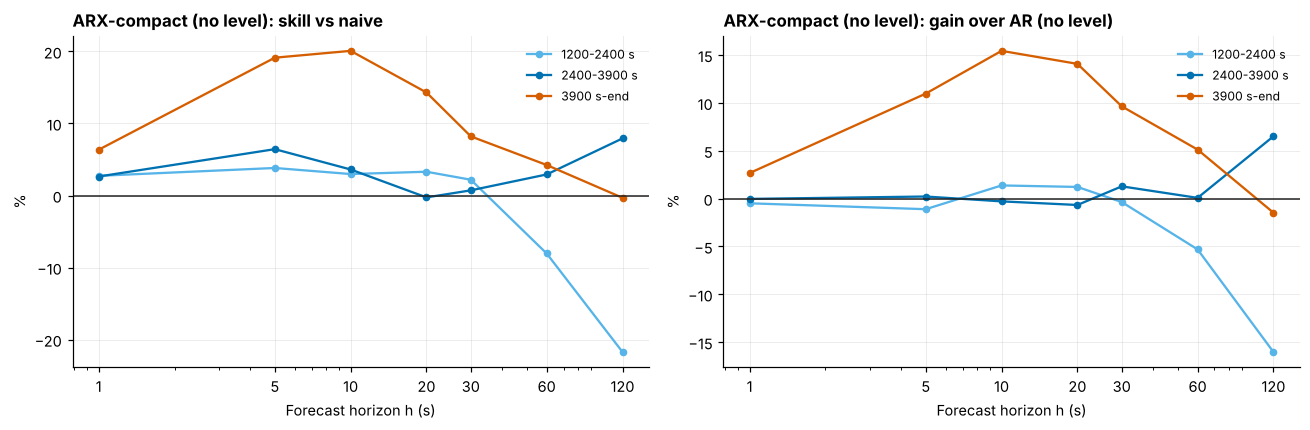

In [34]:
BLOCKS = {"1200-2400 s": (1200, 2400), "2400-3900 s": (2400, 3900), "3900 s-end": (3900, 10**6)}
def block_skill(m, ref="naive"):
    r = {}
    for bn, (a, b) in BLOCKS.items():
        r[bn] = [100 * (1 - H.rmse(ERR[h][m][(ERR[h].index >= a) & (ERR[h].index < b)]) / H.rmse(ERR[h][ref][(ERR[h].index >= a) & (ERR[h].index < b)])) for h in HOR]
    return pd.DataFrame(r, index=HOR).T
T1 = pd.concat({m: block_skill(m) for m in (REF, MAIN, "ARX+speed (no level)")}, axis=0)
display(T1.round(1).style.background_gradient(cmap="RdBu", vmin=-25, vmax=25, axis=None).format("{:.1f}").set_caption("Skill vs naive (%) by time block (columns: horizon, s)"))
T2 = pd.concat({m: block_skill(m, REF) for m in (MAIN, "ARX+speed (no level)")}, axis=0)
display(T2.round(1).style.background_gradient(cmap="RdBu", vmin=-25, vmax=25, axis=None).format("{:.1f}").set_caption("Gain over AR (no level), % by time block"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (bn, c) in zip(BLOCKS, ("#56B4E9", "#0072B2", "#D55E00")):
    ax[0].plot(HOR, block_skill(MAIN).loc[bn], color=c, marker="o", ms=4, label=bn); ax[1].plot(HOR, block_skill(MAIN, REF).loc[bn], color=c, marker="o", ms=4, label=bn)
ax[0].set_title(f"{MAIN}: skill vs naive"); ax[1].set_title(f"{MAIN}: gain over {REF}")
for a in ax: a.axhline(0, color="#222", lw=1); a.set_xscale("log"); a.set_xticks(HOR); a.set_xticklabels(HOR); a.set_xlabel("Forecast horizon h (s)"); a.set_ylabel("%"); a.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

## 4. Sensitivity to design choices
Each configuration changes one choice at a time from the base case and reruns the full rolling-origin evaluation for naive, AR (no level), ARX-compact (no level) and ARX-smooth (no level).

In [35]:
BASE = dict(step=60, start=1200, lam=1.0, mom_s=MOM_S, mom_l=MOM_L, ew=EW)
CONFIGS = {
    "base": {},
    "refit every 30 s": dict(step=30), "refit every 120 s": dict(step=120),
    "evaluation start 900 s": dict(start=900), "evaluation start 1800 s": dict(start=1800),
    "ridge λ = 0.01": dict(lam=0.01), "ridge λ = 100": dict(lam=100.0),
    "sparser momentum lags": dict(mom_s=(1, 5, 30), mom_l=(1, 3, 10, 30)),
    "denser momentum lags": dict(mom_s=(1, 2, 3, 5, 7, 10, 15, 20, 30), mom_l=(1, 2, 3, 4, 5, 7, 10, 15, 20, 30, 45, 60)),
    "faster EWMAs (3, 30)": dict(ew=(3, 30)), "slower EWMAs (10, 120)": dict(ew=(10, 120)),
}
def run_config(cfg):
    c = {**BASE, **cfg}; out = {}
    for h in HOR:
        lo, hi = c["start"], N - h; y = Y[h][lo:hi]; e = {"naive": y}
        for name, cols in (("AR", H.spec(c["mom_l"])), ("ARX-compact", H.spec(c["mom_s"], c["ew"])), ("ARX-smooth", H.spec(c["mom_l"], c["ew"]))):
            e[name] = y - H.rolling_preds(F, Y, cols, h, lo, hi, step=c["step"], lam=c["lam"])
        out[h] = {k: H.rmse(v) for k, v in e.items()}
    return pd.DataFrame(out)
RES = {name: run_config(cfg) for name, cfg in CONFIGS.items()}
sk = lambda m: pd.DataFrame({n: 100 * (1 - r.loc[m] / r.loc["naive"]) for n, r in RES.items()}).T
gn = lambda m: pd.DataFrame({n: 100 * (1 - r.loc[m] / r.loc["AR"]) for n, r in RES.items()}).T
display(sk("ARX-compact").round(1).style.background_gradient(cmap="RdBu", vmin=-12, vmax=12, axis=None).format("{:.1f}").set_caption("ARX-compact (no level): skill vs naive (%), by configuration"))
display(sk("AR").round(1).style.background_gradient(cmap="RdBu", vmin=-12, vmax=12, axis=None).format("{:.1f}").set_caption("AR (no level): skill vs naive (%)"))
display(gn("ARX-compact").round(1).style.background_gradient(cmap="RdBu", vmin=-12, vmax=12, axis=None).format("{:.1f}").set_caption("ARX-compact over AR (no level): gain (%)"))

,1,5,10,20,30,60,120
base,3.8,9.1,8.4,5.9,4.1,1.0,-3.6
refit every 30 s,3.8,9.1,8.3,5.9,3.9,1.0,-3.5
refit every 120 s,3.8,9.1,8.5,6.3,4.5,1.1,-3.6
evaluation start 900 s,3.7,8.7,7.9,5.6,3.5,0.5,-3.0
evaluation start 1800 s,3.5,8.3,7.3,4.6,3.3,1.6,-3.4
ridge λ = 0.01,3.8,9.1,8.4,5.9,4.0,1.0,-3.6
ridge λ = 100,3.8,9.3,8.7,6.4,4.5,1.6,-2.1
sparser momentum lags,3.8,9.2,8.5,6.2,4.2,1.1,-3.5
denser momentum lags,4.1,9.7,8.5,5.8,4.0,1.0,-3.6
"faster EWMAs (3, 30)",3.7,8.8,7.8,5.4,3.7,0.9,-1.6


,1,5,10,20,30,60,120
base,3.2,6.6,3.7,0.8,-0.2,-0.1,-0.2
refit every 30 s,3.2,6.6,3.7,0.7,-0.3,-0.1,-0.4
refit every 120 s,3.2,6.7,3.8,1.0,-0.1,-0.1,0.0
evaluation start 900 s,3.0,6.3,3.6,0.9,-0.2,-0.3,-0.2
evaluation start 1800 s,2.9,6.0,2.9,-0.8,-2.2,0.0,0.5
ridge λ = 0.01,3.2,6.6,3.7,0.8,-0.2,-0.1,-0.2
ridge λ = 100,3.1,6.7,3.8,0.9,-0.1,-0.1,-0.2
sparser momentum lags,3.2,6.6,3.8,1.2,0.3,-0.1,0.0
denser momentum lags,3.1,6.5,3.5,0.6,-0.3,-0.1,-0.2
"faster EWMAs (3, 30)",3.2,6.6,3.7,0.8,-0.2,-0.1,-0.2


,1,5,10,20,30,60,120
base,0.6,2.7,4.9,5.2,4.2,1.1,-3.3
refit every 30 s,0.6,2.6,4.8,5.2,4.2,1.1,-3.1
refit every 120 s,0.6,2.6,4.9,5.3,4.6,1.2,-3.6
evaluation start 900 s,0.6,2.6,4.5,4.8,3.7,0.7,-2.8
evaluation start 1800 s,0.7,2.5,4.5,5.3,5.3,1.6,-3.9
ridge λ = 0.01,0.6,2.6,4.9,5.2,4.2,1.1,-3.4
ridge λ = 100,0.7,2.8,5.1,5.5,4.5,1.6,-2.0
sparser momentum lags,0.7,2.8,4.8,5.0,3.8,1.1,-3.5
denser momentum lags,1.0,3.4,5.2,5.2,4.3,1.1,-3.4
"faster EWMAs (3, 30)",0.5,2.3,4.3,4.6,3.9,1.0,-1.4


In [36]:
S, G = sk("ARX-compact"), gn("ARX-compact")
summ = pd.DataFrame({"min skill": S.min(), "max skill": S.max(), "configs with skill > 0": (S > 0).sum(), "configs where ARX beats AR": (G > 0).sum()}).T
summ.columns = [f"h={h}" for h in HOR]
display(summ.round(1).style.set_caption(f"Across {len(CONFIGS)} configurations (ARX-compact, no level)"))

,h=1,h=5,h=10,h=20,h=30,h=60,h=120
min skill,3.500000,8.300000,7.300000,4.600000,3.300000,-0.400000,-7.300000
max skill,4.100000,9.700000,8.700000,6.400000,4.500000,1.600000,-1.600000
configs with skill > 0,11.000000,11.000000,11.000000,11.000000,11.000000,10.000000,0.000000
configs where ARX beats AR,11.000000,11.000000,11.000000,11.000000,11.000000,10.000000,0.000000


## 5. Reading the results
**1. Reproduction.** The frozen models reproduce the step-4 numbers (e.g. ARX-compact without level: 3.8 / 9.1 / 8.4 / 5.9 / 4.1 / 1.0 / −3.6 % skill at h = 1 … 120 s).

**2. Statistical uncertainty is large.**
- Against naive, ARX-compact (no level) has a bootstrap interval that stays above zero only up to h = 10 s (lower bounds 1.7, 2.4 and 0.3 % at 1, 5 and 10 s). From 20 s on the intervals include zero.
- The gain of power over the AR (no level) model is 0.6 / 2.7 / 4.9 / 5.2 / 4.2 / 1.1 % at h = 1 … 60 s, but **every interval includes zero** (for example 4.9 % with an interval of −1.5 to 11.5 % at 10 s). With one run, "power adds information beyond HR's own history" is therefore suggested but not established by this bootstrap. The HAC Diebold–Mariano tests in step 4 were more favourable; the bootstrap with 200 s blocks (about 20 effective blocks) is the more cautious statement.

**3. The result is mostly a push result.** In the last block (3900 s to the end) ARX-compact beats AR (no level) by 2.7 / 11.0 / 15.4 / 14.1 / 9.6 % at h = 1, 5, 10, 20, 30. In the first two blocks the gain is about zero (between −1.1 and +1.4 % at h ≤ 30). Power carries information mainly when power and HR are changing a lot, which happens in the push. In the first block the longest horizons are poor (−8 % at 60 s, −22 % at 120 s versus naive), so those horizons are not reliable.

**4. Design choices do not drive the result.** Across 11 configurations (refit interval, evaluation start, ridge strength, momentum lags, EWMA spans) the skill of ARX-compact moves by at most about 1.3 percentage points at h ≤ 30 (e.g. 7.3–8.7 % at 10 s). ARX beats AR in all 11 configurations at h ≤ 30, in 10 of 11 at 60 s and in none at 120 s. The only visible sensitivity is to the EWMA spans at the longest horizons.

**What can be claimed in the report**
- A small but consistent improvement over naive at 1–10 s, supported by both the bootstrap and the sensitivity checks.
- Evidence for a benefit of power over HR alone at 5–30 s that is concentrated in the push and statistically uncertain.
- No reliable gain at 60 s and above.
- Everything is conditional on one run and on a specification chosen after seeing the step-4 errors.

---
# Part 4 — Physiological state-space model (step 5b)
*Originally `hr_forecasting_step5b_statespace.ipynb`.*

# Forecasting heart rate from a Garmin run — step 5b: a physiological state-space model
**ISM-E1005 Forecasting Methods in Business Analytics, project work**

The regression models treat HR as a function of its own past and of power. Here the physiology is built into the model. Heart rate relaxes toward a target set by running power, and the target itself can slowly drift (cardiac drift, fatigue, heat):

- latent heart rate: x_{t+1} = (1 − a)·x_t + a·(L_t + g·u_t) + η_t
- target offset: L_{t+1} = L_t + ζ_t (random walk; *switched off* in the no-drift variant)
- observed heart rate: y_t = x_t + ε_t

Here a = 1/τ is the relaxation rate (τ is the time constant in seconds), g is the steady-state gain in bpm per watt, and u_t is the power input (a trailing EWMA(5) of power or raw power). The filter is a Kalman filter. Parameters are estimated by maximum likelihood.

**Why this may fix the problem seen in step 4.** The regression with an HR level term pulled forecasts toward the steady-stretch HR. Here the offset L_t is *tracked*, so if HR sits higher for the same power in the push, the filter learns that and the forecast target moves with it.

**Forecasting.** With power held at its last value, the h-step forecast has a closed form: the current latent HR is blended with the target, x̂_{t+h|t} = (1 − a)^h·x̂_t + (1 − (1 − a)^h)·(L̂_t + g·u_t). Beyond the first step this needs future power. The honest, fully ex-ante versions therefore *forecast power too*:
- **persistence:** future power = last observed power;
- **mean-reverting:** future power = the 60 s EWMA level.

A third version, **oracle**, uses the *actual* future power. It is not a forecast. It is a conditional ("planned workout") benchmark that shows how much of the model's error is due to not knowing future power.

**Evaluation** is identical to step 4: origins from t = 1200 s, errors in HR units. Parameters are re-estimated every 300 s using only data up to that time, and the Kalman filter is run forward with those fixed parameters, so the state at each origin uses only the past.

In [37]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import hrlib as H, hrss

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "grid.linewidth": .6, "lines.linewidth": 1.5, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5})
HOR = H.HORIZONS; T_START = 1200; STEP_SS = 300
df = H.load(); N = len(df); y = df.hr.astype(float).values
F = H.build_features(df); Y = H.targets(df.hr.astype(float))
U = {"raw": F["p0"].values, "ewma5": F["pew5"].values}
print("Observations:", N, "| power input variants:", list(U))

Observations: 5313 | power input variants: ['raw', 'ewma5']


## 1. Full-sample fit (descriptive)
The first fit uses the whole run. It is **descriptive only** (in-sample) and is used for the parameter interpretation and the input-delay check, not for forecasting.

In [38]:
def fit(yy, uu, drift, delay=0, start=None):
    m = hrss.HRStateSpace(yy, uu, drift=drift, delay=delay)
    return m.fit(start_params=start, method="lbfgs", maxiter=400, disp=False)

rows = []
for inp in U:
    for drift in (False, True, 0.2, 0.05):
        r = fit(y, U[inp], drift)
        a, g, se, sz, sv = r.params
        rows.append(dict(input=inp, drift=drift, tau_s=1 / a, gain_bpm_per_W=g, sd_eta=se, sd_zeta=(0.0 if drift is False else (sz if drift is True else drift)), sd_eps=sv, loglik=r.llf, AIC=r.aic, converged=r.mle_retvals["converged"]))
FULL = pd.DataFrame(rows).set_index(["input", "drift"])
display(FULL.round(3))
print("Reference from step 2: distributed-lag step response reached 63% after ~51 s with gain ~0.17 bpm/W; first-order regression gave tau ~128 s.")

tau_s  gain_bpm_per_W  sd_eta  sd_zeta  sd_eps    loglik  \
input drift                                                               
raw   False  128.581           0.359   0.605    0.000   0.000 -4881.354   
      True    12.110           0.038   0.545    1.246   0.001 -4824.504   
      0.2     74.511           0.220   0.603    0.200   0.001 -4869.390   
      0.05   102.815           0.298   0.604    0.050   0.001 -4877.030   
ewma5 False  124.070           0.351   0.607    0.000   0.000 -4893.044   
      True    10.330           0.044   0.539    1.150   0.000 -4813.584   
      0.2     66.493           0.205   0.603    0.200   0.000 -4877.430   
      0.05    95.680           0.285   0.605    0.050   0.000 -4887.568   

                  AIC  converged  
input drift                       
raw   False  9772.709       True  
      True   9659.008       True  
      0.2    9748.780       True  
      0.05   9764.059       True  
ewma5 False  9796.089       True  
      True   9637.168       True  
      0.2    9764.860       True  
      0.05   9785.135       True

Reference from step 2: distributed-lag step response reached 63% after ~51 s with gain ~0.17 bpm/W; first-order regression gave tau ~128 s.


**Reading note.** The "slow drift" rows fix the noise of the offset at a small value instead of estimating it. They were added after seeing that the estimated-drift fit lets the offset absorb most of the variation (see section 5), so they are **exploratory**.

### 1.1 Input delay
The delay *d* is the number of seconds between a power value and its first effect on HR. It is chosen using **only the first 1200 s** (the initial training window) so that no later data influences it. The full-sample values are shown for information.

In [39]:
DELAYS = [0, 2, 5, 8, 12, 16, 20]
rows = []
for d in DELAYS:
    r0 = fit(y[:T_START + 1], U["ewma5"][:T_START + 1], True, d); r1 = fit(y, U["ewma5"], True, d)
    rows.append(dict(delay=d, loglik_first_1200s=r0.llf, loglik_full=r1.llf, tau_full=1 / r1.params[0], gain_full=r1.params[1]))
DEL = pd.DataFrame(rows).set_index("delay"); display(DEL.round(2))
D_SEL = int(DEL.loglik_first_1200s.idxmax()); print("Delay selected on the first 1200 s:", D_SEL, "s")

,loglik_first_1200s,loglik_full,tau_full,gain_full
delay,,,,
0,-1193.49,-4813.58,10.33,0.04
2,-1194.73,-4824.73,9.16,0.04
5,-1196.72,-4834.77,8.06,0.03
8,-1197.43,-4786.06,4.39,0.02
12,-1200.24,-4798.80,4.67,0.01
16,-1200.89,-4799.85,4.66,0.01
20,-1202.49,-4859.43,8.04,0.01


Delay selected on the first 1200 s: 0 s


## 2. Rolling-origin estimation and filtering

In [40]:
def ss_rolling(u, drift, delay):
    """Re-estimate every STEP_SS s on data up to the refit time; filter forward with those parameters."""
    xh, Lh = np.full(N, np.nan), np.full(N, np.nan); PAR = np.full((N, 5), np.nan); prev = None; bad = 0
    for tb in range(T_START, N, STEP_SS):
        te = min(tb + STEP_SS, N)
        r = fit(y[:tb + 1], u[:tb + 1], drift, delay, start=prev); bad += (not r.mle_retvals["converged"]); prev = r.params
        fs = hrss.HRStateSpace(y[:te], u[:te], drift=drift, delay=delay).filter(r.params).filtered_state
        xh[tb:te], Lh[tb:te], PAR[tb:te] = fs[0, tb:te], fs[1, tb:te], r.params
    return dict(x=xh, L=Lh, par=PAR, nonconverged=bad)

VARIANTS = {"raw / no drift": ("raw", False), "raw / drift": ("raw", True), "EWMA5 / no drift": ("ewma5", False), "EWMA5 / drift": ("ewma5", True),
            "EWMA5 / slow drift (sd 0.2)": ("ewma5", 0.2), "EWMA5 / slow drift (sd 0.05)": ("ewma5", 0.05)}
FIT = {k: ss_rolling(U[inp], dr, D_SEL) for k, (inp, dr) in VARIANTS.items()}
print({k: v["nonconverged"] for k, v in FIT.items()}, "non-converged refits per variant")

# Leakage check: the filtered state at time t must not depend on data after t
t_chk = 3000; r = fit(y[:t_chk + 1], U["ewma5"][:t_chk + 1], True, D_SEL)
a1 = hrss.HRStateSpace(y[:t_chk + 1], U["ewma5"][:t_chk + 1], True, D_SEL).filter(r.params).filtered_state[:, t_chk]
y2 = y.copy(); y2[t_chk + 1:] *= 1.5
a2 = hrss.HRStateSpace(y2[:t_chk + 300], U["ewma5"][:t_chk + 300], True, D_SEL).filter(r.params).filtered_state[:, t_chk]
print("Filtered state at t unchanged when future data are corrupted:", bool(np.allclose(a1, a2)))

{'raw / no drift': 0, 'raw / drift': 0, 'EWMA5 / no drift': 0, 'EWMA5 / drift': 0, 'EWMA5 / slow drift (sd 0.2)': 0, 'EWMA5 / slow drift (sd 0.05)': 0} non-converged refits per variant


Filtered state at t unchanged when future data are corrupted: True


In [41]:
def ss_forecast(fit_, u, h, mode):
    lo, hi = T_START, N - h; t = np.arange(lo, hi)
    x, L, A, G = fit_["x"][lo:hi].copy(), fit_["L"][lo:hi], fit_["par"][lo:hi, 0], fit_["par"][lo:hi, 1]
    pew60 = F["pew60"].values
    for j in range(h):
        idx = t + j - D_SEL                                        # input driving the step from t+j to t+j+1
        if mode == "persist": idx = np.minimum(idx, t)             # unknown future power replaced by last value
        elif mode == "mean60":                                     # unknown future power replaced by the 60 s EWMA level
            uu = np.where(idx <= t, u[np.clip(idx, 0, None)], pew60[t]); x = (1 - A) * x + A * (L + G * uu); continue
        x = (1 - A) * x + A * (L + G * u[np.clip(idx, 0, None)])   # mode == "oracle": actual future power
    return x                                                       # forecast of the level HR(t+h)

ERR = {}
for h in HOR:
    lo, hi = T_START, N - h; act = y[lo + h:hi + h]; base = y[lo:hi]; E = {"naive": act - base}
    E["AR (no level)"] = (Y[h][lo:hi] - H.rolling_preds(F, Y, H.spec((1, 2, 3, 5, 10, 20, 30, 60)), h, lo, hi))
    E["ARX-compact (no level)"] = (Y[h][lo:hi] - H.rolling_preds(F, Y, H.spec((1, 5, 10, 30), (5, 60)), h, lo, hi))
    for k, (inp, dr) in VARIANTS.items():
        E[f"SS {k}"] = act - ss_forecast(FIT[k], U[inp], h, "persist")
    E["SS EWMA5 / drift, power→EWMA60"] = act - ss_forecast(FIT["EWMA5 / drift"], U["ewma5"], h, "mean60")
    E["[oracle] SS EWMA5 / drift, true future power"] = act - ss_forecast(FIT["EWMA5 / drift"], U["ewma5"], h, "oracle")
    ERR[h] = pd.DataFrame(E, index=np.arange(lo, hi))
print("Origins per horizon:", {h: len(ERR[h]) for h in HOR}, "| NaN:", any(ERR[h].isna().any().any() for h in HOR))

Origins per horizon: {1: 4112, 5: 4108, 10: 4103, 20: 4093, 30: 4083, 60: 4053, 120: 3993} | NaN: False


## 3. Results

In [42]:
ORDER = list(ERR[1].columns)
RMSE = pd.DataFrame({h: np.sqrt((ERR[h] ** 2).mean()) for h in HOR}).loc[ORDER]
SKILL = 100 * (1 - RMSE / RMSE.loc["naive"])
star = lambda p: "*" if p < 0.05 else ""
display(RMSE.round(2).style.format("{:.2f}").set_caption("RMSE (bpm)"))
tab = pd.DataFrame({h: {m: f"{SKILL.loc[m, h]:.1f}{star(H.dm(ERR[h][m], ERR[h]['naive'], h)[1])}" for m in ORDER[1:]} for h in HOR})
display(tab.style.set_caption("Skill vs naive (%); * = DM p < 0.05 vs naive"))
REF = "ARX-compact (no level)"
GAIN = 100 * (1 - RMSE / RMSE.loc[REF])
tab2 = pd.DataFrame({h: {m: f"{GAIN.loc[m, h]:.1f}{star(H.dm(ERR[h][m], ERR[h][REF], h)[1])}" for m in ORDER if m not in ("naive", REF)} for h in HOR})
display(tab2.style.set_caption(f"Gain over {REF} (%); positive = state-space better; * = DM p < 0.05"))

,1,5,10,20,30,60,120
naive,0.60,1.61,2.66,4.14,5.15,6.72,8.43
AR (no level),0.58,1.51,2.56,4.11,5.16,6.73,8.45
ARX-compact (no level),0.58,1.47,2.44,3.90,4.94,6.65,8.73
SS raw / no drift,0.59,1.52,2.46,3.96,5.30,8.31,12.15
SS raw / drift,0.58,1.47,2.48,3.98,5.07,6.73,8.51
SS EWMA5 / no drift,0.59,1.54,2.51,4.05,5.40,8.29,11.99
SS EWMA5 / drift,0.58,1.47,2.46,3.95,5.04,6.71,8.49
SS EWMA5 / slow drift (sd 0.2),0.59,1.51,2.45,3.90,5.15,7.62,10.39
SS EWMA5 / slow drift (sd 0.05),0.59,1.52,2.47,3.97,5.28,7.99,11.27
"SS EWMA5 / drift, power→EWMA60",0.58,1.63,2.78,4.35,5.37,6.90,8.57


,1,5,10,20,30,60,120
AR (no level),3.2*,6.6*,3.7,0.8,-0.2,-0.1,-0.2
ARX-compact (no level),3.8*,9.1*,8.4*,5.9,4.1,1.0,-3.6
SS raw / no drift,1.9*,5.9*,7.4*,4.3,-2.9,-23.6,-44.1*
SS raw / drift,2.6*,8.8*,6.8*,3.9*,1.6,-0.0,-1.0
SS EWMA5 / no drift,1.6*,4.8*,5.7*,2.2,-5.0,-23.3,-42.2*
SS EWMA5 / drift,2.7*,9.2*,7.5*,4.5*,2.2,0.2,-0.7
SS EWMA5 / slow drift (sd 0.2),2.1*,6.5*,8.1*,5.8,-0.1,-13.4,-23.2
SS EWMA5 / slow drift (sd 0.05),1.9*,5.8*,7.1*,4.1,-2.6,-18.9,-33.6*
"SS EWMA5 / drift, power→EWMA60",2.7*,-1.1,-4.6*,-5.0*,-4.2*,-2.6*,-1.7
"[oracle] SS EWMA5 / drift, true future power",2.7*,9.9*,9.3*,8.0*,6.9,7.0,8.3*


,1,5,10,20,30,60,120
AR (no level),-0.6,-2.7,-5.1,-5.5,-4.4,-1.1,3.2
SS raw / no drift,-2.0*,-3.5,-1.1,-1.8,-7.3,-24.9,-39.2
SS raw / drift,-1.3*,-0.3,-1.8,-2.2,-2.6,-1.1,2.5
SS EWMA5 / no drift,-2.3*,-4.7*,-3.0,-4.0,-9.4,-24.6,-37.3
SS EWMA5 / drift,-1.1*,0.1,-1.0,-1.5,-1.9,-0.8,2.8
SS EWMA5 / slow drift (sd 0.2),-1.7*,-2.8,-0.3,-0.2,-4.3,-14.6,-19.0
SS EWMA5 / slow drift (sd 0.05),-2.0*,-3.7,-1.5,-2.0,-6.9,-20.1,-29.0
"SS EWMA5 / drift, power→EWMA60",-1.1*,-11.2*,-14.2*,-11.7*,-8.6*,-3.6,1.8
"[oracle] SS EWMA5 / drift, true future power",-1.1*,0.9,1.0,2.2,2.9,6.0,11.4*


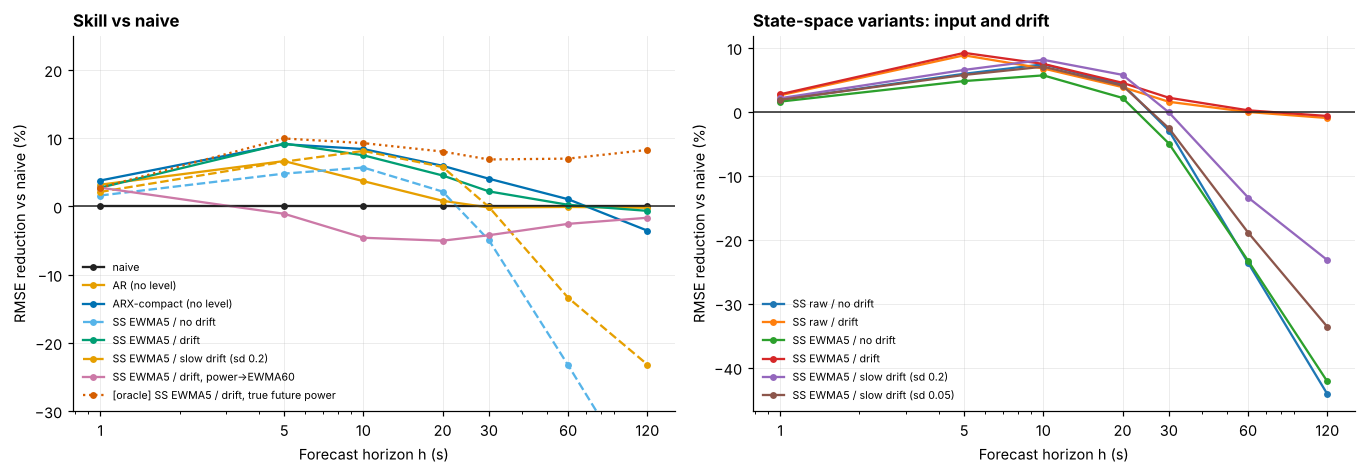

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.4))
sty = {"naive": ("#222222", "-"), "AR (no level)": ("#E69F00", "-"), "ARX-compact (no level)": ("#0072B2", "-"),
       "SS EWMA5 / no drift": ("#56B4E9", "--"), "SS EWMA5 / drift": ("#009E73", "-"), "SS EWMA5 / slow drift (sd 0.2)": ("#E69F00", "--"), "SS EWMA5 / drift, power→EWMA60": ("#CC79A7", "-"),
       "[oracle] SS EWMA5 / drift, true future power": ("#D55E00", ":")}
for m, (c, ls) in sty.items():
    ax[0].plot(HOR, SKILL.loc[m], color=c, ls=ls, marker="o", ms=3.5, label=m)
ax[0].axhline(0, color="#222", lw=1); ax[0].set_title("Skill vs naive"); ax[0].set_ylabel("RMSE reduction vs naive (%)"); ax[0].set_ylim(-30, 25)
for m in ("SS raw / no drift", "SS raw / drift", "SS EWMA5 / no drift", "SS EWMA5 / drift", "SS EWMA5 / slow drift (sd 0.2)", "SS EWMA5 / slow drift (sd 0.05)"):
    ax[1].plot(HOR, SKILL.loc[m], marker="o", ms=3.5, label=m)
ax[1].axhline(0, color="#222", lw=1); ax[1].set_title("State-space variants: input and drift"); ax[1].set_ylabel("RMSE reduction vs naive (%)")
for a in ax: a.set_xscale("log"); a.set_xticks(HOR); a.set_xticklabels(HOR); a.set_xlabel("Forecast horizon h (s)"); a.legend(frameon=False, fontsize=7)
fig.tight_layout(); plt.show()

### 3.1 By time block
Same three blocks as in step 5a, so the two notebooks can be compared directly.

In [44]:
BLOCKS = {"1200-2400 s": (1200, 2400), "2400-3900 s": (2400, 3900), "3900 s-end": (3900, 10**6)}
def block_skill(m, ref="naive"):
    r = {}
    for bn, (a, b) in BLOCKS.items():
        r[bn] = [100 * (1 - H.rmse(ERR[h][m][(ERR[h].index >= a) & (ERR[h].index < b)]) / H.rmse(ERR[h][ref][(ERR[h].index >= a) & (ERR[h].index < b)])) for h in HOR]
    return pd.DataFrame(r, index=HOR).T
ms = ("ARX-compact (no level)", "SS EWMA5 / no drift", "SS EWMA5 / drift", "SS EWMA5 / slow drift (sd 0.2)")
T = pd.concat({m: block_skill(m) for m in ms}, axis=0)
display(T.round(1).style.background_gradient(cmap="RdBu", vmin=-25, vmax=25, axis=None).format("{:.1f}").set_caption("Skill vs naive (%) by time block (columns: horizon, s)"))

## 4. What the model has learned
### 4.1 Parameters across refits
If τ and the gain move a lot from refit to refit, the interpretation should be treated carefully.

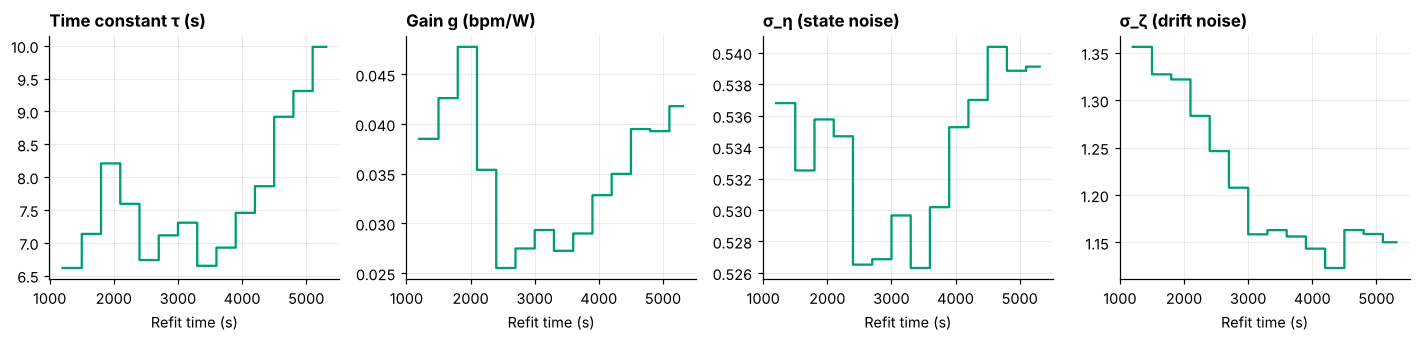

,τ (s),gain,σ_η,σ_ζ,σ_ε
refit time (s),,,,,
1200,6.615,0.039,0.537,1.356,0.0
1500,7.134,0.043,0.533,1.327,0.0
1800,8.208,0.048,0.536,1.322,0.0
2100,7.593,0.035,0.535,1.283,0.0
2400,6.736,0.026,0.527,1.246,0.0
2700,7.112,0.027,0.527,1.208,0.0
3000,7.305,0.029,0.530,1.159,0.0
3300,6.648,0.027,0.526,1.163,0.0
3600,6.925,0.029,0.530,1.156,0.0


In [45]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
P = FIT["EWMA5 / drift"]["par"]; tt = np.arange(N); ok = ~np.isnan(P[:, 0])
for a, (j, ttl, tr) in zip(ax, ((0, "Time constant τ (s)", lambda v: 1 / v), (1, "Gain g (bpm/W)", lambda v: v), (2, "σ_η (state noise)", lambda v: v), (3, "σ_ζ (drift noise)", lambda v: v))):
    a.step(tt[ok], tr(P[ok, j]), where="post", color="#009E73"); a.set_title(ttl); a.set_xlabel("Refit time (s)")
fig.tight_layout(); plt.show()
display(pd.DataFrame({"τ (s)": 1 / P[ok, 0], "gain": P[ok, 1], "σ_η": P[ok, 2], "σ_ζ": P[ok, 3], "σ_ε": P[ok, 4]}, index=tt[ok]).iloc[::300].round(3).rename_axis("refit time (s)").head(14))

### 4.2 The tracked offset (cardiac drift)
The filtered offset L̂_t (the part of the HR target not explained by power) from the full-sample fit with estimated drift noise. If L̂ were a clean measure of cardiac drift it should rise slowly through the run. This plot is descriptive. (Observed and filtered HR coincide because the estimated measurement noise is essentially zero.)

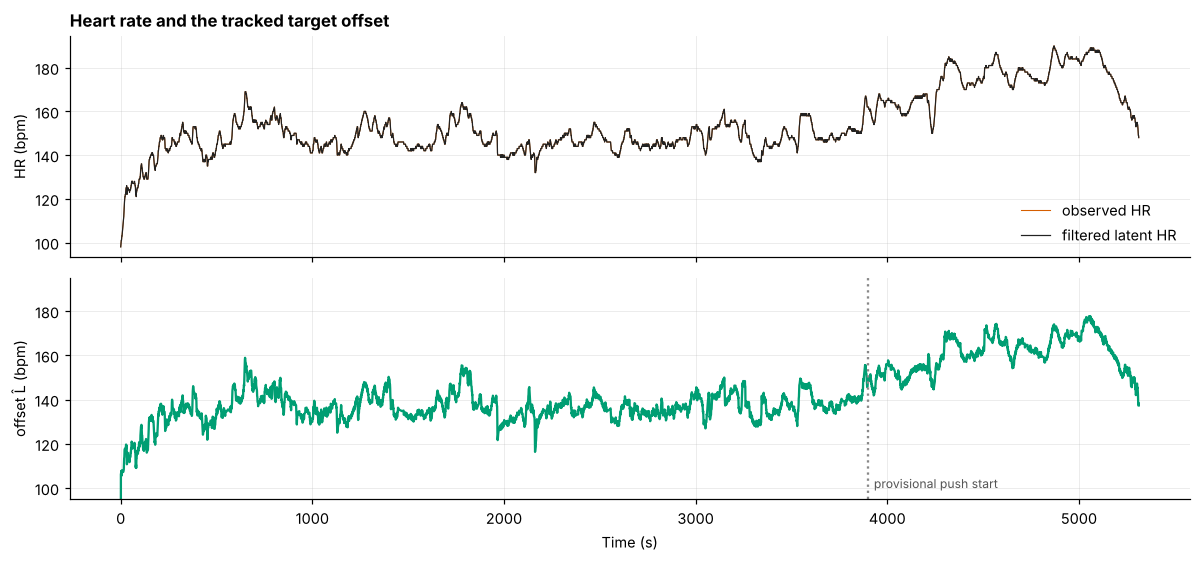

In [46]:
r = fit(y, U["ewma5"], True, D_SEL)
fs = hrss.HRStateSpace(y, U["ewma5"], True, D_SEL).filter(r.params).filtered_state
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
ax[0].plot(y, color="#D55E00", lw=.7, label="observed HR"); ax[0].plot(fs[0], color="#222", lw=.8, label="filtered latent HR"); ax[0].set_ylabel("HR (bpm)"); ax[0].legend(frameon=False, loc="lower right"); ax[0].set_title("Heart rate and the tracked target offset")
ax[1].plot(fs[1], color="#009E73"); ax[1].set_ylim(95, 195); ax[1].set_ylabel("offset L̂ (bpm)"); ax[1].set_xlabel("Time (s)")
ax[1].axvline(3900, color="#888", ls=":"); ax[1].text(3930, 100, "provisional push start", fontsize=8, color="#555")
fig.tight_layout(); plt.show()

## 5. Reading the results
**Parameters**
- **No drift:** τ ≈ 125–130 s and gain ≈ 0.35–0.36 bpm/W. This is the same as the first-order regression in step 2 (τ ≈ 128 s, gain ≈ 0.36), so the Kalman-filter fit reproduces it.
- **Estimated drift:** the fit is much better (AIC 9,637 vs 9,796), but the parameters stop being physiological: τ collapses to 10–12 s and the gain to 0.04 bpm/W. The offset's noise is large (≈ 1.2 bpm per √s), so L̂ simply follows HR itself (the offset plot is about HR minus 10 bpm) and the model behaves like a local-level model with a tiny power effect. τ and the gain in this variant should **not** be interpreted physiologically.
- **Slow drift (noise fixed at 0.2 or 0.05, exploratory):** τ ≈ 66–96 s and gain ≈ 0.2–0.29 bpm/W, close to the step-2 distributed-lag result (63 % of the response after ≈ 51 s, gain ≈ 0.17). These are interpretable, but see below for their forecasts.
- **Delay:** d = 0 was selected on the first 1200 s. The full-sample likelihood prefers 8–16 s in the drift fits, so the delay is not pinned down; I did not pursue it.

**Forecast accuracy**
- **No gain over the regression.** The best ex-ante state-space variant (EWMA(5) input, estimated drift) has skill 2.7 / 9.2 / 7.5 / 4.5 / 2.2 / 0.2 / −0.7 % at h = 1 … 120 s, versus 3.8 / 9.1 / 8.4 / 5.9 / 4.1 / 1.0 / −3.6 % for ARX-compact (no level). It is slightly worse at short horizons and slightly better at 120 s, but none of the differences at h ≥ 5 is significant.
- **Without a drift state the model fails in the push:** skill is −23 % at 60 s and −42 to −44 % at 120 s (significant). This is the same failure as the regression with an HR level term in step 4, and it supports that explanation: a fixed power-implied target does not hold once the push starts. In the first time block, however, the no-drift model is the best of all at 10–30 s (7.9 / 10.3 / 7.0 %), while it is the worst in the last block. It works while the HR–power relation holds.
- **The slow-drift variants fall in between** (−13 % and −23 % at 60 and 120 s for noise 0.2). So the variants with interpretable parameters extrapolate badly across the push, and the one that extrapolates well has non-physiological parameters.

**Future power is the bottleneck**
- Replacing future power by its 60 s mean is much worse than holding power at its last value (e.g. −11 % relative to ARX-compact at 5 s). Persistence of the current power carries real information.
- The **oracle** version (true future power, not a forecast) reaches 9.9 / 9.3 / 8.0 / 6.9 / 7.0 / 8.3 % skill at h = 5 … 120 s, i.e. +6.0 % at 60 s and +11.4 % (significant) at 120 s over ARX-compact. The physiology does carry long-horizon information, but only if power itself can be predicted, which it cannot here.

**Conclusion for the report.** The state-space model gives a physiological reading of the results and links them to the step-2 lag estimates, but it does not forecast better than the no-level ARX models. The two are nearly equivalent when drift is estimated. The honest message is that the long-horizon limit comes from drift in the HR–power relationship and from the unpredictability of future power, not from the choice of model class. As in the earlier steps, this rests on one run, and the slow-drift variants were added after seeing the first results.

---
# Part 5 — Report figures
Regenerates the five figures used in the report (saved as PNG files in `report_figs/`) with the same code as the standalone `report_figs.py`. This part recomputes the main models once more on the common specification, so it takes about a minute.

In [47]:
import warnings; warnings.filterwarnings("ignore")
import os, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, statsmodels.api as sm
from statsmodels.tsa.ar_model import ar_select_order, AutoReg
import hrlib as H

OUT = "report_figs"; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "grid.linewidth": .6, "lines.linewidth": 1.3, "axes.titlesize": 9.5, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "font.size": 8.5, "axes.labelsize": 8.5})
COL = {"hr": "#D55E00", "power": "#0072B2", "speed": "#009E73", "cadence_spm": "#CC79A7", "altitude": "#6B6B6B"}
df = H.load(); N = len(df); hr = df.hr.astype(float); F = H.build_features(df); Y = H.targets(hr); HOR = H.HORIZONS
SEG = {"warm-up": (0, 600), "steady": (600, 3900), "push": (3900, 5100), "cool-down": (5100, 5313)}
def shade(ax, label=False):
    for (n, (a, b)), c in zip(SEG.items(), ["#00000000", "#00000012", "#00000000", "#00000012"]):
        ax.axvspan(a, b, color=c, lw=0)
        if label: ax.text((a + b) / 2, 1.0, n, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7, color="#555")

## Figure 1 — the five series with phases

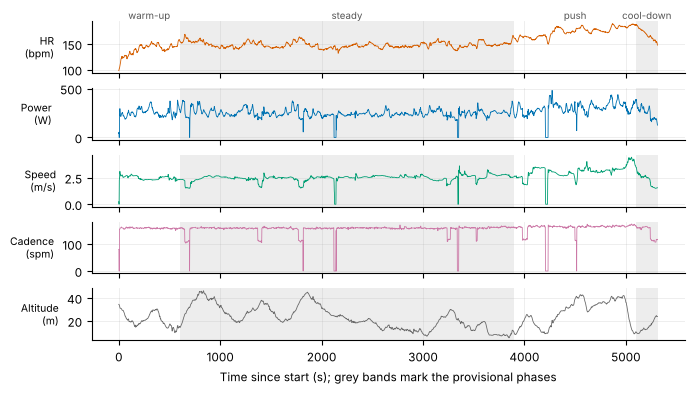

In [48]:
# ---- Figure 1: the five series with phases
fig, axes = plt.subplots(5, 1, figsize=(7, 4.0), sharex=True)
lab = {"hr": "HR\n(bpm)", "power": "Power\n(W)", "speed": "Speed\n(m/s)", "cadence_spm": "Cadence\n(spm)", "altitude": "Altitude\n(m)"}
for i, (ax, v) in enumerate(zip(axes, lab)):
    shade(ax, i == 0); ax.plot(df.index, df[v], color=COL[v], lw=.6); ax.set_ylabel(lab[v], rotation=0, ha="right", va="center", fontsize=7.5, labelpad=6)
axes[-1].set_xlabel("Time since start (s); grey bands mark the provisional phases"); fig.tight_layout(h_pad=.4); fig.savefig(f"{OUT}/fig1_series.png"); plt.show()

## Figure 2 — lag structure

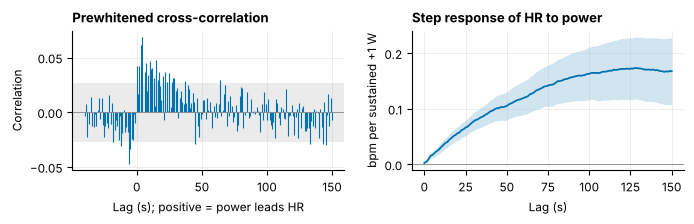

In [49]:
# ---- Figure 2: lag structure (prewhitened CCF and step response)
def prewhiten_ccf(x, y, maxpos=150, maxneg=40, ar_max=40):
    x = x.dropna().values; y = y.dropna().values
    sel = ar_select_order(x, maxlag=ar_max, ic="aic", trend="n"); p = max(sel.ar_lags)
    phi = AutoReg(x, lags=p, trend="n").fit().params
    def filt(z): n = len(z); return z[p:] - sum(phi[i - 1] * z[p - i:n - i] for i in range(1, p + 1))
    a, b = filt(x), filt(y); n = len(a); ks = np.arange(-maxneg, maxpos + 1)
    r = np.array([np.corrcoef(a[:n - k], b[k:])[0, 1] if k >= 0 else np.corrcoef(a[-k:], b[:n + k])[0, 1] for k in ks])
    return ks, r, 1.96 / np.sqrt(n)
ks, r, band = prewhiten_ccf(df.power.diff(), df.hr.diff())
K = 150; d_ = pd.DataFrame({"dhr": hr.diff()})
for k in range(K + 1): d_[f"dp{k}"] = df.power.astype(float).diff().shift(k)
d_ = d_.dropna(); dl = sm.OLS(d_.dhr, sm.add_constant(d_.drop(columns="dhr"))).fit(cov_type="HAC", cov_kwds={"maxlags": 30})
b = dl.params.drop("const").values; V = dl.cov_params().drop("const").drop(columns="const").values
L = np.tril(np.ones((K + 1, K + 1))); cum = L @ b; se = np.sqrt(np.diag(L @ V @ L.T)); kk = np.arange(K + 1)
fig, ax = plt.subplots(1, 2, figsize=(7, 2.3))
ax[0].axhspan(-band, band, color="#00000014", lw=0); ax[0].vlines(ks, 0, r, color=COL["power"], lw=.8); ax[0].axhline(0, color="#888", lw=.6)
ax[0].set_title("Prewhitened cross-correlation"); ax[0].set_xlabel("Lag (s); positive = power leads HR"); ax[0].set_ylabel("Correlation")
ax[1].fill_between(kk, cum - 1.96 * se, cum + 1.96 * se, color=COL["power"], alpha=.18, lw=0); ax[1].plot(kk, cum, color=COL["power"]); ax[1].axhline(0, color="#888", lw=.6)
ax[1].set_title("Step response of HR to power"); ax[1].set_xlabel("Lag (s)"); ax[1].set_ylabel("bpm per sustained +1 W")
fig.tight_layout(); fig.savefig(f"{OUT}/fig2_lag.png"); plt.show()

## Models behind Figures 3–5

In [50]:
# ---- Models for figures 3-5
MOM_S, MOM_L, EW = (1, 5, 10, 30), (1, 2, 3, 5, 10, 20, 30, 60), (5, 60)
SPEC = {"AR (no level)": H.spec(MOM_L), "ARX-compact (no level)": H.spec(MOM_S, EW), "ARX-smooth (level)": H.spec(MOM_L, EW, level=True)}
ERR = {}
for h in HOR:
    lo, hi = 1200, N - h; y = Y[h][lo:hi]; E = {"naive": y}
    for n, c in SPEC.items(): E[n] = y - H.rolling_preds(F, Y, c, h, lo, hi)
    ERR[h] = pd.DataFrame(E, index=np.arange(lo, hi))
RM = pd.DataFrame({h: np.sqrt((ERR[h] ** 2).mean()) for h in HOR})
MAIN, REF = "ARX-compact (no level)", "AR (no level)"

## Figure 3 — skill vs horizon with bootstrap bands

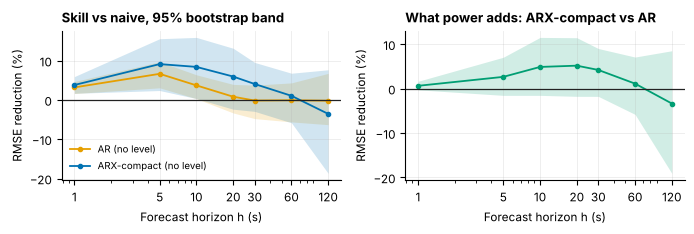

In [51]:
# ---- Figure 3: skill with bootstrap bands
rows = []
for h in HOR:
    bs = np.sqrt(H.block_boot([ERR[h]["naive"].values ** 2, ERR[h][MAIN].values ** 2, ERR[h][REF].values ** 2], L=200, B=2000, seed=h))
    sm_, sr_, g_ = 100 * (1 - bs[:, 1] / bs[:, 0]), 100 * (1 - bs[:, 2] / bs[:, 0]), 100 * (1 - bs[:, 1] / bs[:, 2])
    rows.append(dict(main=100 * (1 - RM.loc[MAIN, h] / RM.loc["naive", h]), ml=np.percentile(sm_, 2.5), mh=np.percentile(sm_, 97.5),
                     ref=100 * (1 - RM.loc[REF, h] / RM.loc["naive", h]), rl=np.percentile(sr_, 2.5), rh=np.percentile(sr_, 97.5),
                     gain=100 * (1 - RM.loc[MAIN, h] / RM.loc[REF, h]), gl=np.percentile(g_, 2.5), gh=np.percentile(g_, 97.5)))
B = pd.DataFrame(rows, index=HOR)
fig, ax = plt.subplots(1, 2, figsize=(7, 2.4))
for k, lo_, hi_, c, nm in (("ref", "rl", "rh", "#E69F00", "AR (no level)"), ("main", "ml", "mh", "#0072B2", "ARX-compact (no level)")):
    ax[0].fill_between(HOR, B[lo_], B[hi_], color=c, alpha=.18, lw=0); ax[0].plot(HOR, B[k], color=c, marker="o", ms=3, label=nm)
ax[0].axhline(0, color="#222", lw=.9); ax[0].set_title("Skill vs naive, 95% bootstrap band"); ax[0].set_ylabel("RMSE reduction (%)"); ax[0].legend(frameon=False, fontsize=7)
ax[1].fill_between(HOR, B.gl, B.gh, color="#009E73", alpha=.18, lw=0); ax[1].plot(HOR, B.gain, color="#009E73", marker="o", ms=3)
ax[1].axhline(0, color="#222", lw=.9); ax[1].set_title("What power adds: ARX-compact vs AR"); ax[1].set_ylabel("RMSE reduction (%)")
for a in ax: a.set_xscale("log"); a.set_xticks(HOR); a.set_xticklabels(HOR); a.set_xlabel("Forecast horizon h (s)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_skill.png"); plt.show()

## Figure 4 — stability across time blocks

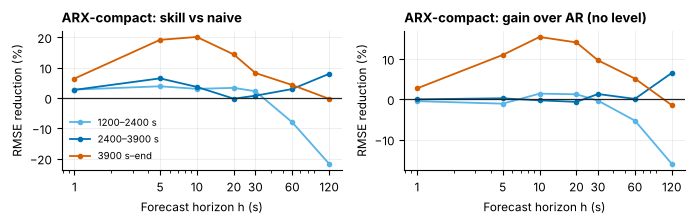

In [52]:
# ---- Figure 4: time blocks
BL = {"1200–2400 s": (1200, 2400), "2400–3900 s": (2400, 3900), "3900 s–end": (3900, 10**6)}
def bsk(m, ref):
    out = {}
    for n, (a, b_) in BL.items():
        out[n] = [100 * (1 - H.rmse(ERR[h][m][(ERR[h].index >= a) & (ERR[h].index < b_)]) / H.rmse(ERR[h][ref][(ERR[h].index >= a) & (ERR[h].index < b_)])) for h in HOR]
    return out
fig, ax = plt.subplots(1, 2, figsize=(7, 2.3))
for (n, v), c in zip(bsk(MAIN, "naive").items(), ("#56B4E9", "#0072B2", "#D55E00")): ax[0].plot(HOR, v, color=c, marker="o", ms=3, label=n)
for (n, v), c in zip(bsk(MAIN, REF).items(), ("#56B4E9", "#0072B2", "#D55E00")): ax[1].plot(HOR, v, color=c, marker="o", ms=3, label=n)
ax[0].set_title("ARX-compact: skill vs naive"); ax[1].set_title("ARX-compact: gain over AR (no level)")
for a in ax: a.axhline(0, color="#222", lw=.9); a.set_xscale("log"); a.set_xticks(HOR); a.set_xticklabels(HOR); a.set_xlabel("Forecast horizon h (s)"); a.set_ylabel("RMSE reduction (%)")
ax[0].legend(frameon=False, fontsize=7); fig.tight_layout(); fig.savefig(f"{OUT}/fig4_blocks.png"); plt.show()

## Figure 5 — example 30 s forecasts

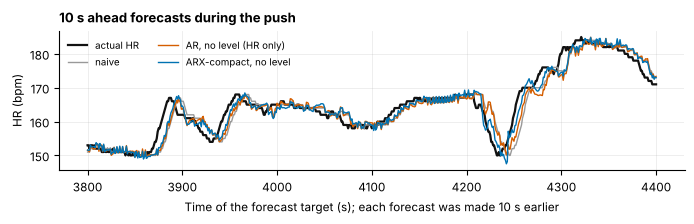

done
     main    ml    mh  ref   rl   rh  gain    gl    gh
1     3.8   1.7   5.9  3.2  1.6  4.7   0.6  -0.3   1.6
5     9.1   2.4  15.6  6.6  3.1  9.7   2.7  -1.5   7.1
10    8.4   0.3  15.9  3.7  0.3  6.4   4.9  -1.5  11.5
20    5.9  -2.4  13.1  0.8 -3.3  3.9   5.2  -1.7  11.5
30    4.1  -2.9   9.5 -0.2 -4.8  3.8   4.2  -1.7   9.0
60    1.0  -5.8   6.8 -0.1 -5.6  4.3   1.1  -5.8   7.1
120  -3.6 -18.7   7.7 -0.2 -6.3  6.8  -3.3 -19.1   8.5


In [53]:
# ---- Figure 5: example forecasts, h = 10 s
h = 10; t0, t1 = 3800, 4400; idx = ERR[h].index[(ERR[h].index + h >= t0) & (ERR[h].index + h <= t1)]
fig, ax = plt.subplots(figsize=(7, 2.3)); ax.plot(idx + h, hr.values[idx + h], color="#111", lw=1.6, label="actual HR")
for m, c, nm in (("naive", "#999999", "naive"), (REF, "#D55E00", "AR, no level (HR only)"), (MAIN, "#0072B2", "ARX-compact, no level")):
    ax.plot(idx + h, hr.values[idx + h] - ERR[h].loc[idx, m].values, color=c, lw=1.0, label=nm)
ax.set_xlabel("Time of the forecast target (s); each forecast was made 10 s earlier"); ax.set_ylabel("HR (bpm)"); ax.set_title("10 s ahead forecasts during the push"); ax.legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(f"{OUT}/fig5_example.png"); plt.show()
print("done"); print(B.round(1).to_string())

---
# Part 6 — Choosing one "best" model and plotting its forecasts
**Selection rule (stated before looking at the table below):** among forecasting models (no oracle), pick the one with the highest *average skill across the horizons 1–60 s*, and check that the choice is not an artefact of one horizon, one time block or one close competitor. The 120 s horizon is left out of the main criterion because no model beats the naïve forecast there; it is still reported.

Caveat: the candidates are compared on the same test period, and the no-level versions were added after seeing earlier test errors, so the winner's skill is somewhat optimistic (see the limitations in the report).

In [54]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import hrlib as H
df = H.load(); N = len(df); hr = df.hr.astype(float); F = H.build_features(df); Y = H.targets(hr); HOR = H.HORIZONS
ML, MS = (1, 2, 3, 5, 10, 20, 30, 60), (1, 5, 10, 30)
CAND = {}
for lv in (True, False):
    s = " (level)" if lv else " (no level)"
    CAND["AR-small" + s] = H.spec(MS, level=lv); CAND["AR-large" + s] = H.spec(ML, level=lv)
    CAND["ARX-compact" + s] = H.spec(MS, (5, 60), level=lv); CAND["ARX-smooth" + s] = H.spec(ML, (5, 60), level=lv)
    CAND["ARX-compact+speed" + s] = H.spec(MS, (5, 60), level=lv, speed=True); CAND["ARX-smooth+speed" + s] = H.spec(ML, (5, 60), level=lv, speed=True)
    CAND["ARX-power-lags" + s] = (["hr"] if lv else []) + [f"d{k}" for k in ML] + [f"p{k}" for k in (0, 1, 2, 3, 5, 10, 20, 30, 60)]
CERR = {}
for h in HOR:
    lo, hi = 1200, N - h; y = Y[h][lo:hi]; E = {"naive": y}
    for n, c in CAND.items(): E[n] = y - H.rolling_preds(F, Y, c, h, lo, hi)
    CERR[h] = pd.DataFrame(E, index=np.arange(lo, hi))
R = pd.DataFrame({h: np.sqrt((CERR[h] ** 2).mean()) for h in HOR})
S = (100 * (1 - R / R.loc["naive"])).drop(index="naive")
S["mean 1-60 s"] = S[[1, 5, 10, 20, 30, 60]].mean(axis=1); S["mean 1-30 s"] = S[[1, 5, 10, 20, 30]].mean(axis=1)
S["horizons > naive"] = (S[HOR] > 0).sum(axis=1)
BLOCKS = {"1200-2400 s": (1200, 2400), "2400-3900 s": (2400, 3900), "3900 s-end": (3900, 10**6)}
def block_skill(m, a, b): return np.mean([100 * (1 - H.rmse(CERR[h][m][(CERR[h].index >= a) & (CERR[h].index < b)]) / H.rmse(CERR[h]["naive"][(CERR[h].index >= a) & (CERR[h].index < b)])) for h in (1, 5, 10, 20, 30)])
for k, (a, b) in BLOCKS.items(): S["block " + k] = [block_skill(m, a, b) for m in S.index]
S = S.sort_values("mean 1-60 s", ascending=False)
display(S.round(1).style.format("{:.1f}").format("{:.0f}", subset=["horizons > naive"]).background_gradient(cmap="Blues", subset=["mean 1-60 s"]).set_caption("Skill vs naive (%), forecasting models only; block columns = mean skill over h = 1-30 s inside each time block"))
BEST = S.index[0]; print("Selected by the rule:", BEST)

,1,5,10,20,30,60,120,mean 1-60 s,mean 1-30 s,horizons > naive,block 1200-2400 s,block 2400-3900 s,block 3900 s-end
ARX-compact (no level),3.8,9.1,8.4,5.9,4.1,1.0,-3.6,5.4,6.3,6,3.0,2.6,13.6
ARX-smooth (no level),4.1,9.6,8.2,5.2,3.0,0.4,-4.8,5.1,6.0,6,2.6,2.4,13.4
ARX-power-lags (no level),3.8,8.8,7.1,4.5,3.0,0.6,-3.6,4.6,5.4,6,2.0,2.4,12.2
ARX-smooth (level),4.2,9.6,8.0,4.5,1.7,-3.3,-13.0,4.1,5.6,5,7.7,6.2,4.7
ARX-compact (level),3.9,9.0,7.9,4.7,2.1,-3.1,-12.1,4.1,5.5,5,7.4,6.2,4.9
ARX-power-lags (level),3.9,8.7,6.7,3.3,1.5,-3.1,-12.5,3.5,4.8,5,7.1,6.0,3.3
ARX-compact+speed (level),3.6,7.5,5.1,1.8,1.7,-2.5,-10.0,2.9,3.9,5,6.7,7.0,0.3
ARX-compact+speed (no level),3.5,7.5,5.1,1.2,0.9,-1.7,-6.6,2.7,3.6,5,6.2,3.6,2.7
ARX-smooth+speed (level),3.8,7.6,4.6,1.4,1.5,-2.7,-10.3,2.7,3.8,5,6.5,7.2,-0.2
ARX-smooth+speed (no level),3.8,7.9,4.9,0.7,0.3,-2.5,-7.2,2.5,3.5,5,6.2,3.9,2.0


Selected by the rule: ARX-compact (no level)


In [55]:
# Is the winner clearly better than its closest competitors? Diebold-Mariano on squared errors, HAC, per horizon
rows = {}
for rival in [m for m in S.index[1:4]] + ["AR-large (no level)"]:
    rows[rival] = {h: H.dm(CERR[h][BEST], CERR[h][rival], h)[1] for h in HOR}
P = pd.DataFrame(rows).T
display(P.round(2).style.format("{:.2f}").set_caption(f"p-values, {BEST} vs rival (two-sided DM; small = the two differ)"))
print("Positive mean(d) in dm() means the winner has the LARGER squared error; read the skill table for the direction.")

,1,5,10,20,30,60,120
ARX-smooth (no level),0.05,0.03,0.52,0.14,0.16,0.32,0.23
ARX-power-lags (no level),0.85,0.30,0.01,0.02,0.22,0.75,0.97
ARX-smooth (level),0.15,0.69,0.85,0.63,0.56,0.50,0.30
AR-large (no level),0.08,0.09,0.05,0.08,0.09,0.70,0.59


Positive mean(d) in dm() means the winner has the LARGER squared error; read the skill table for the direction.


**Reading the selection**
- The rule picks **ARX-compact (no level)**: highest average skill over 1–60 s and over 1–30 s, and it beats the naïve forecast at six of the seven horizons.
- It is *not* uniformly best. The ARX-smooth versions are slightly ahead at 1–5 s, and the DM p-values show the differences between the top no-level ARX models are small and mostly not significant from 10 s onward. The simpler ARX-compact is preferred on parsimony.
- The ranking depends on the part of the run. In the two steady blocks the *with-level* models do better against naïve (about 6–8%) than the no-level models (about 2–3%), because mean reversion works while HR is stable. In the push the no-level models win by a wide margin (about 13% against about 5%). The pooled test period is dominated by the push, where errors are largest, so the pooled winner is a no-level model.
- All of this is conditional on one run; see the limitations.

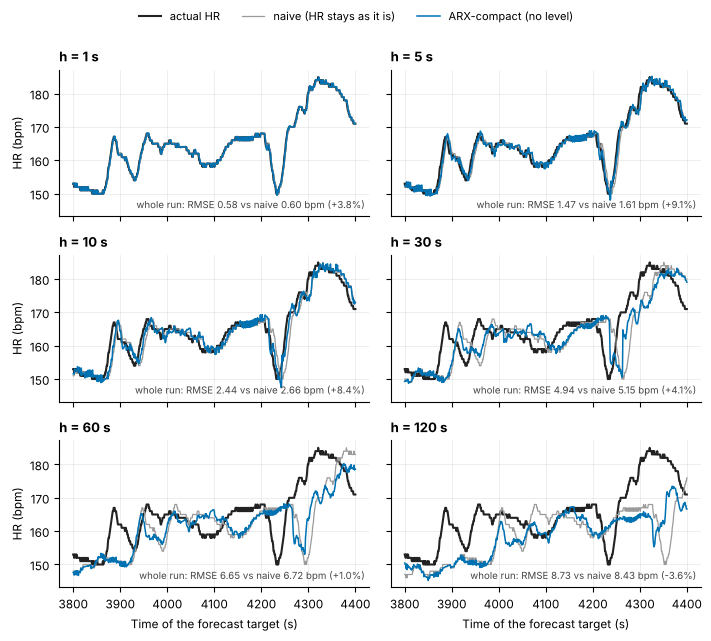

In [56]:
# Figure 6: forecasts of the selected model against actual HR, several horizons (push, 3,800-4,400 s)
import os; os.makedirs("report_figs", exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "grid.linewidth": .6, "font.size": 8.5, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlelocation": "left"})
HS, T0, T1 = [1, 5, 10, 30, 60, 120], 3800, 4400
fig, axes = plt.subplots(3, 2, figsize=(7.2, 6.4), sharex=True, sharey=True)
for ax, h in zip(axes.ravel(), HS):
    e = CERR[h]; idx = e.index[(e.index + h >= T0) & (e.index + h <= T1)]; act = hr.values[idx + h]
    ax.plot(idx + h, act, color="#222222", lw=1.5, label="actual HR")
    ax.plot(idx + h, act - e.loc[idx, "naive"].values, color="#9A9A9A", lw=.9, label="naive (HR stays as it is)")
    ax.plot(idx + h, act - e.loc[idx, BEST].values, color="#0072B2", lw=1.1, label=BEST)
    rm, rn = H.rmse(e[BEST]), H.rmse(e["naive"])
    ax.set_title(f"h = {h} s"); ax.text(.985, .04, f"whole run: RMSE {rm:.2f} vs naive {rn:.2f} bpm ({100*(1-rm/rn):+.1f}%)", transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color="#444444")
for ax in axes[-1]: ax.set_xlabel("Time of the forecast target (s)")
for ax in axes[:, 0]: ax.set_ylabel("HR (bpm)")
h_, l_ = axes[0, 0].get_legend_handles_labels(); fig.legend(h_, l_, loc="upper center", ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0, 1, .95)); fig.savefig("report_figs/fig6_best_model_forecasts.png", dpi=220); plt.show()

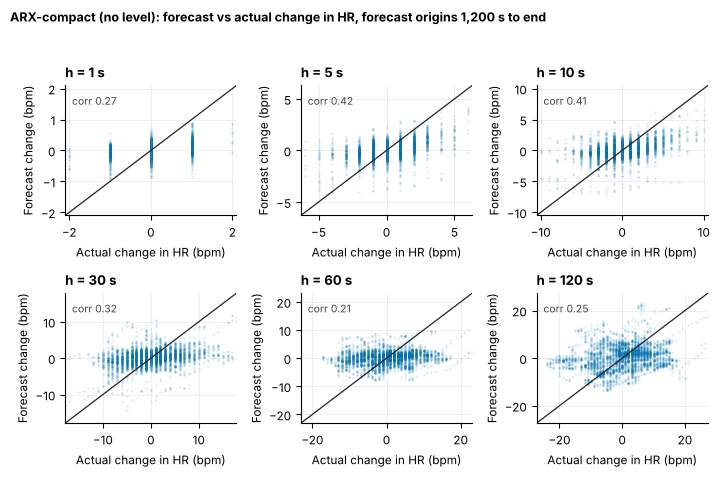

In [57]:
# Figure 7: predicted vs actual change in HR over the whole test period (a perfect forecast lies on the diagonal)
fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.8))
for ax, h in zip(axes.ravel(), HS):
    e = CERR[h]; actual = e["naive"].values; pred = actual - e[BEST].values
    lim = np.percentile(np.abs(actual), 99.5) * 1.05
    ax.scatter(actual, pred, s=3, alpha=.15, color="#0072B2", linewidths=0)
    ax.plot([-lim, lim], [-lim, lim], color="#222222", lw=.9); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    r = np.corrcoef(actual, pred)[0, 1]; ax.set_title(f"h = {h} s"); ax.text(.04, .93, f"corr {r:.2f}", transform=ax.transAxes, fontsize=7.5, color="#444444", va="top")
    ax.set_xlabel("Actual change in HR (bpm)"); ax.set_ylabel("Forecast change (bpm)")
fig.suptitle(f"{BEST}: forecast vs actual change in HR, forecast origins 1,200 s to end", fontsize=9, fontweight="bold", x=.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, .95)); fig.savefig("report_figs/fig7_best_model_scatter.png", dpi=220); plt.show()